### Imports

In [1]:
import os
from time import time
from datetime import timedelta
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from dython.nominal import associations
from sklearn.model_selection import train_test_split, cross_validate, GridSearchCV, StratifiedKFold, cross_val_predict, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import KNNImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.decomposition import PCA
from sklearn.metrics import (classification_report, roc_auc_score, average_precision_score, confusion_matrix, f1_score, make_scorer,
    RocCurveDisplay, PrecisionRecallDisplay, accuracy_score, precision_score, recall_score, silhouette_score)
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC, LinearSVR
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.inspection import permutation_importance
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
import optuna
from sklearn.utils import resample
from IPython.core.interactiveshell import InteractiveShell

# Notebook configuration
InteractiveShell.ast_node_interactivity = "all"
pd.set_option('display.precision', 4)

C:\Users\usuario\AppData\Roaming\Python\Python312\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Exploratory Data Analysis

## Initial information

In [3]:
df = pd.read_csv("../data/bank-additional-full.csv", header=0, delimiter=';')
print(df.head())

   age        job  marital    education  default housing loan    contact  \
0   56  housemaid  married     basic.4y       no      no   no  telephone   
1   57   services  married  high.school  unknown      no   no  telephone   
2   37   services  married  high.school       no     yes   no  telephone   
3   40     admin.  married     basic.6y       no      no   no  telephone   
4   56   services  married  high.school       no      no  yes  telephone   

  month day_of_week  ...  campaign  pdays  previous     poutcome emp.var.rate  \
0   may         mon  ...         1    999         0  nonexistent          1.1   
1   may         mon  ...         1    999         0  nonexistent          1.1   
2   may         mon  ...         1    999         0  nonexistent          1.1   
3   may         mon  ...         1    999         0  nonexistent          1.1   
4   may         mon  ...         1    999         0  nonexistent          1.1   

   cons.price.idx  cons.conf.idx  euribor3m  nr.employed

In [32]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

In [33]:
df.describe()

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41188.0000,41188.0000,41188.0000,41188.0000,41188.0000,41188.0000,41188.0000,41188.0000,41188.0000,41188.0000
mean,40.0241,258.2850,2.5676,962.4755,0.1730,0.0819,93.5757,-40.5026,3.6213,5167.0359
std,10.4212,259.2792,2.7700,186.9109,0.4949,1.5710,0.5788,4.6282,1.7344,72.2515
min,17.0000,0.0000,1.0000,0.0000,0.0000,-3.4000,92.2010,-50.8000,0.6340,4963.6000
25%,32.0000,102.0000,1.0000,999.0000,0.0000,-1.8000,93.0750,-42.7000,1.3440,5099.1000
50%,38.0000,180.0000,2.0000,999.0000,0.0000,1.1000,93.7490,-41.8000,4.8570,5191.0000
75%,47.0000,319.0000,3.0000,999.0000,0.0000,1.4000,93.9940,-36.4000,4.9610,5228.1000
max,98.0000,4918.0000,56.0000,999.0000,7.0000,1.4000,94.7670,-26.9000,5.0450,5228.1000


In [34]:
print(df.duplicated().sum())
df[df.duplicated()]

12


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
1266,39,blue-collar,married,basic.6y,no,no,no,telephone,may,thu,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.855,5191.0,no
12261,36,retired,married,unknown,no,no,no,telephone,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.966,5228.1,no
14234,27,technician,single,professional.course,no,no,no,cellular,jul,mon,...,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
16956,47,technician,divorced,high.school,no,yes,no,cellular,jul,thu,...,3,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
18465,32,technician,single,professional.course,no,yes,no,cellular,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,no
20216,55,services,married,high.school,unknown,no,no,cellular,aug,mon,...,1,999,0,nonexistent,1.4,93.444,-36.1,4.965,5228.1,no
20534,41,technician,married,professional.course,no,yes,no,cellular,aug,tue,...,1,999,0,nonexistent,1.4,93.444,-36.1,4.966,5228.1,no
25217,39,admin.,married,university.degree,no,no,no,cellular,nov,tue,...,2,999,0,nonexistent,-0.1,93.200,-42.0,4.153,5195.8,no
28477,24,services,single,high.school,no,yes,no,cellular,apr,tue,...,1,999,0,nonexistent,-1.8,93.075,-47.1,1.423,5099.1,no
32516,35,admin.,married,university.degree,no,yes,no,cellular,may,fri,...,4,999,0,nonexistent,-1.8,92.893,-46.2,1.313,5099.1,no


## Understand distributions

### Numerical variables

<Axes: xlabel='y', ylabel='age'>

<Axes: xlabel='y', ylabel='duration'>

<Axes: xlabel='y', ylabel='campaign'>

<Axes: xlabel='y', ylabel='pdays'>

<Axes: xlabel='y', ylabel='previous'>

<Axes: xlabel='y', ylabel='emp.var.rate'>

<Axes: xlabel='y', ylabel='cons.price.idx'>

<Axes: xlabel='y', ylabel='cons.conf.idx'>

<Axes: xlabel='y', ylabel='euribor3m'>

<Axes: xlabel='y', ylabel='nr.employed'>

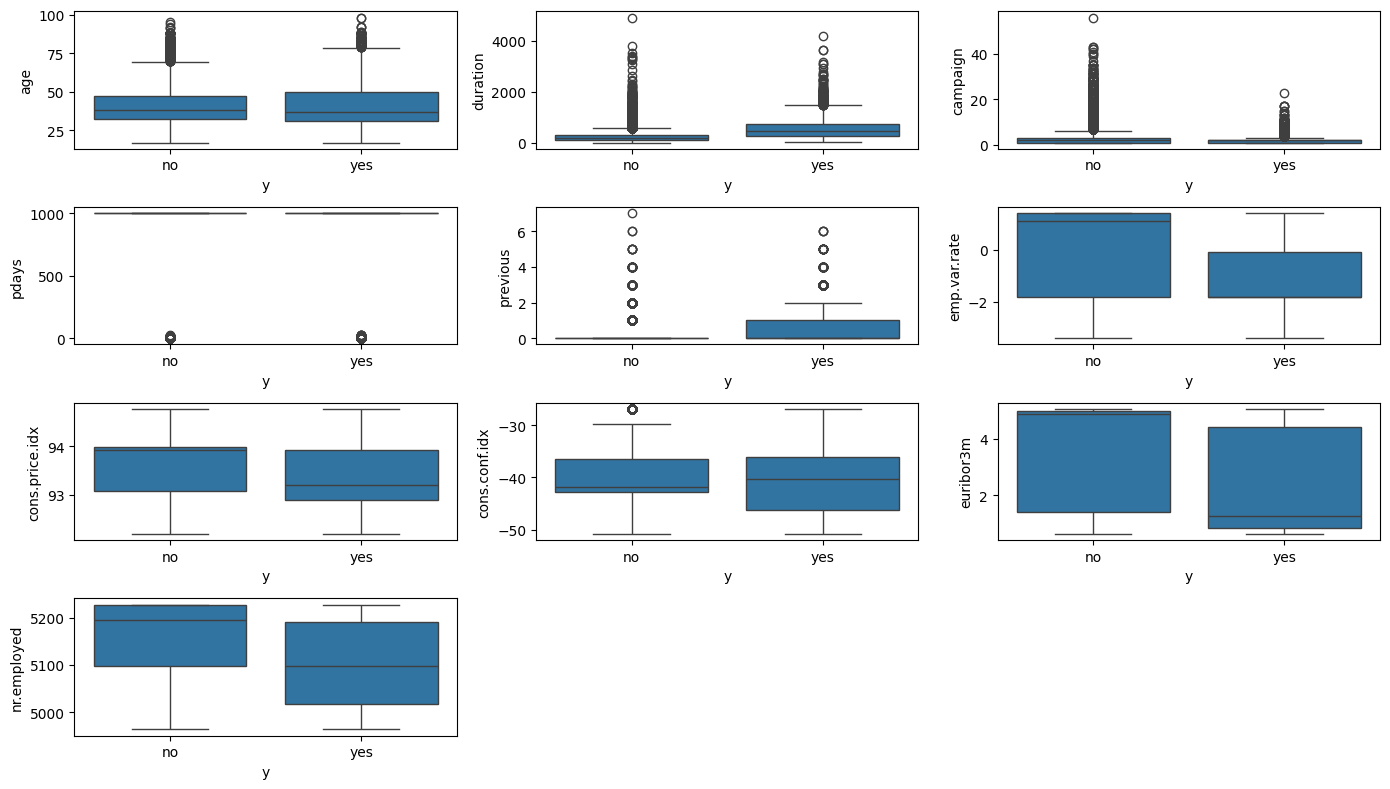

In [35]:
categorical_columns = df.select_dtypes(include=['object', 'string']).columns
numerical_columns = df.select_dtypes(include=['int64', 'float64']).columns

# Numerical variables
fig, axes = plt.subplots(4, 3, figsize=(14, 8))
axes = axes.flatten()

for i, c in enumerate(numerical_columns):
    sns.boxplot(x='y', y=c, data=df, ax=axes[i])

# --- THE FIX ---
# Loop through the remaining axes and delete them
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

### Categorical variables

<Axes: xlabel='job'>

Text(0.5, 1.0, 'job')

[Text(0, 0, 'admin.'),
 Text(1, 0, 'blue-collar'),
 Text(2, 0, 'entrepreneur'),
 Text(3, 0, 'housemaid'),
 Text(4, 0, 'management'),
 Text(5, 0, 'retired'),
 Text(6, 0, 'self-employed'),
 Text(7, 0, 'services'),
 Text(8, 0, 'student'),
 Text(9, 0, 'technician'),
 Text(10, 0, 'unemployed'),
 Text(11, 0, 'unknown')]

<Axes: xlabel='marital'>

Text(0.5, 1.0, 'marital')

[Text(0, 0, 'divorced'),
 Text(1, 0, 'married'),
 Text(2, 0, 'single'),
 Text(3, 0, 'unknown')]

... (20 outputs left out)

[Text(0, 0, 'fri'),
 Text(1, 0, 'mon'),
 Text(2, 0, 'thu'),
 Text(3, 0, 'tue'),
 Text(4, 0, 'wed')]

<Axes: xlabel='poutcome'>

Text(0.5, 1.0, 'poutcome')

[Text(0, 0, 'failure'), Text(1, 0, 'nonexistent'), Text(2, 0, 'success')]

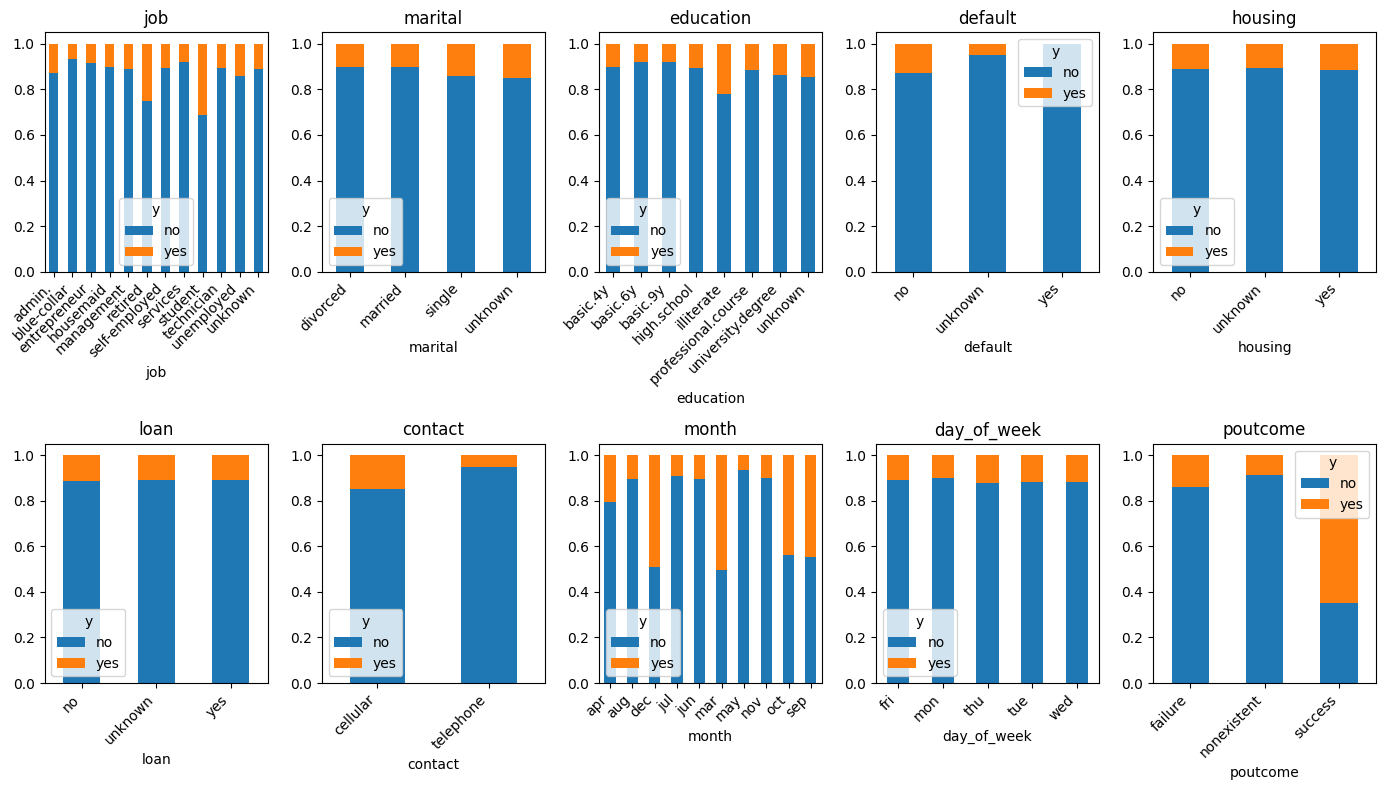

In [36]:
# Categorical variables
fig, axes = plt.subplots(2, 5, figsize=(14, 8))
axes = axes.flatten()

for i, c in enumerate(categorical_columns[:-1]):
    ct = pd.crosstab(df[c], df['y'], normalize='index')
    ct.plot(kind='bar', stacked=True, ax=axes[i])
    axes[i].set_title(c)
    
    # --- THE FIX ---
    # Rotate labels by 45 degrees and align them to the right
    axes[i].set_xticklabels(axes[i].get_xticklabels(), rotation=45, ha='right')

# Clean up any leftover empty axes (just in case)
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

## Missing values

In [37]:
df.isna().sum()

age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64

In [38]:
# Check for 'unknown' values in categorical columns
for col in categorical_columns:
    n = (df[col] == 'unknown').sum()
    if n > 0:
        print(f"{col}: {n} unknowns ({100*n/len(df):.1f}%)")

job: 330 unknowns (0.8%)
marital: 80 unknowns (0.2%)
education: 1731 unknowns (4.2%)
default: 8597 unknowns (20.9%)
housing: 990 unknowns (2.4%)
loan: 990 unknowns (2.4%)


## Correlations

### Between explanatory variables

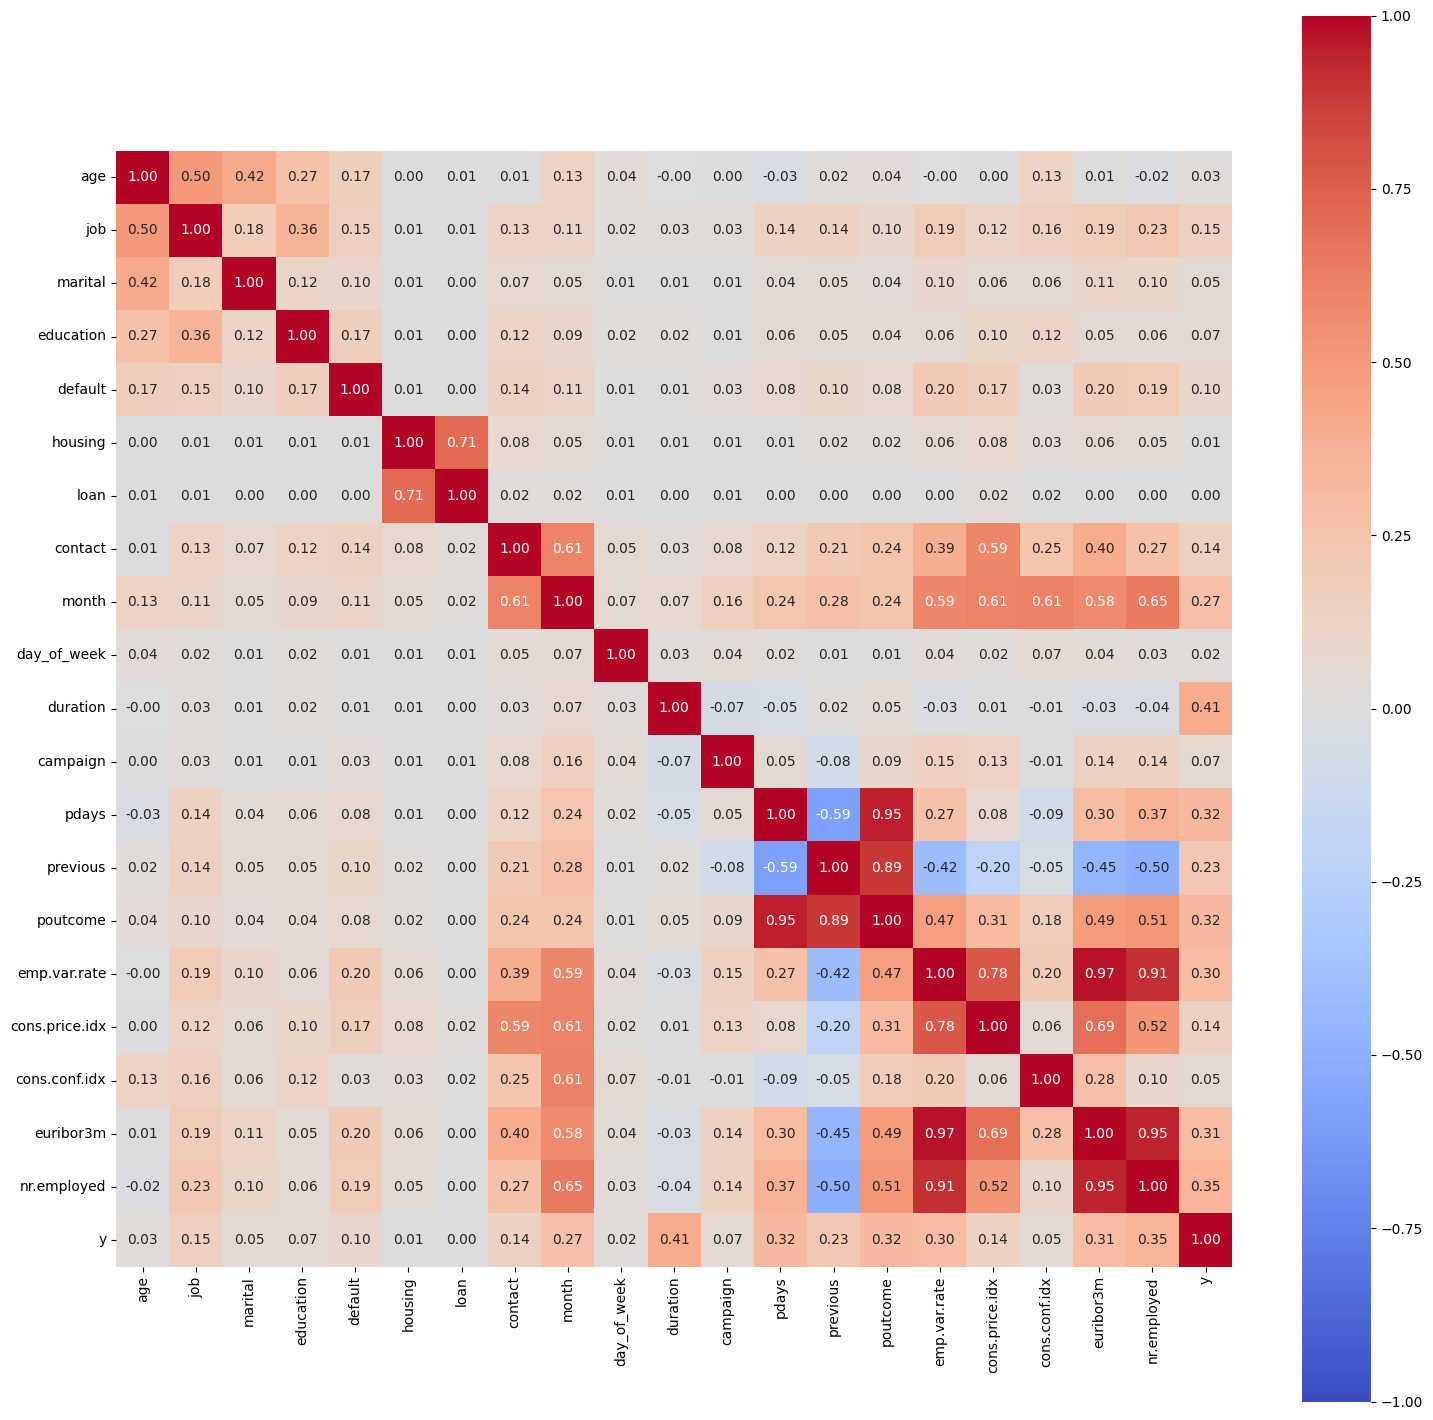

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
age,1.0000,0.5048,0.4189,0.2685,0.1650,0.0020,0.0074,0.0070,0.1263,0.0379,...,0.0046,-0.0344,0.0244,0.0356,-0.0004,0.0009,0.1294,0.0108,-0.0177,0.0304
job,0.5048,1.0000,0.1836,0.3595,0.1521,0.0106,0.0102,0.1279,0.1098,0.0165,...,0.0300,0.1412,0.1353,0.0996,0.1935,0.1233,0.1583,0.1950,0.2259,0.1519
marital,0.4189,0.1836,1.0000,0.1162,0.0954,0.0092,0.0000,0.0720,0.0502,0.0109,...,0.0131,0.0427,0.0503,0.0366,0.1001,0.0639,0.0634,0.1101,0.1028,0.0539
education,0.2685,0.3595,0.1162,1.0000,0.1704,0.0133,0.0000,0.1233,0.0947,0.0197,...,0.0074,0.0563,0.0497,0.0423,0.0609,0.1047,0.1163,0.0530,0.0573,0.0672
default,0.1650,0.1521,0.0954,0.1704,1.0000,0.0106,0.0016,0.1356,0.1119,0.0113,...,0.0332,0.0801,0.1026,0.0766,0.2033,0.1683,0.0268,0.1953,0.1898,0.0991
housing,0.0020,0.0106,0.0092,0.0133,0.0106,1.0000,0.7079,0.0846,0.0542,0.0146,...,0.0110,0.0107,0.0217,0.0170,0.0602,0.0820,0.0345,0.0593,0.0459,0.0095
loan,0.0074,0.0102,0.0000,0.0000,0.0016,0.7079,1.0000,0.0242,0.0198,0.0061,...,0.0053,0.0020,0.0042,0.0000,0.0035,0.0171,0.0151,0.0029,0.0043,0.0000
contact,0.0070,0.1279,0.0720,0.1233,0.1356,0.0846,0.0242,1.0000,0.6091,0.0549,...,0.0774,0.1180,0.2128,0.2424,0.3936,0.5915,0.2516,0.3998,0.2692,0.1446
month,0.1263,0.1098,0.0502,0.0947,0.1119,0.0542,0.0198,0.6091,1.0000,0.0666,...,0.1608,0.2403,0.2806,0.2424,0.5882,0.6084,0.6123,0.5781,0.6483,0.2740
day_of_week,0.0379,0.0165,0.0109,0.0197,0.0113,0.0146,0.0061,0.0549,0.0666,1.0000,...,0.0403,0.0159,0.0058,0.0146,0.0353,0.0191,0.0667,0.0438,0.0299,0.0232


In [39]:
output = associations(df, nan_strategy='drop_samples', figsize=(18,18), cmap='coolwarm')

correlation = output['corr']
ax = output['ax']

correlation

## Class imbalance

(36548, 21)
(4640, 21)


<Axes: xlabel='y'>

Text(0.5, 1.0, 'Class distribution')

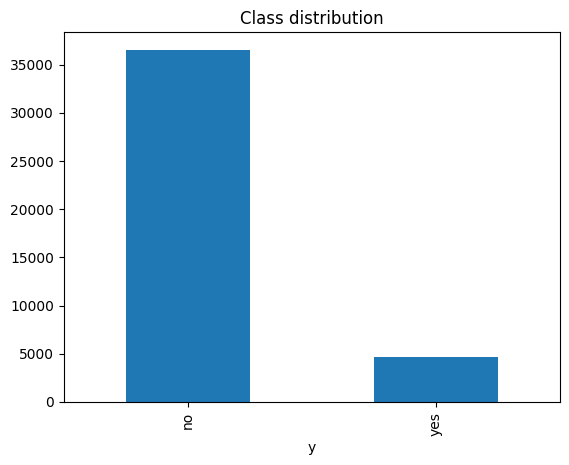

In [40]:
print(df[df['y']=='no'].shape)
print(df[df['y']=='yes'].shape)

df['y'].value_counts().plot(kind='bar')
plt.title('Class distribution')

# Data preprocessing


## General preprocessing

In [41]:
def find_outliers(df, numerical_columns):
    for col in numerical_columns:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        small_outliers = df[col] < lower_bound
        big_outliers = df[col] > upper_bound
        n_small = small_outliers.sum()
        n_big = big_outliers.sum()
        if n_small > 0 or n_big > 0:
            print(f'In column {col}, there are {n_small} small and {n_big} big outliers')

def general_preprocessing(df):
    
    df = df.copy()
    print(f'Initial shape: {df.shape}')
    
    print('Removing duplicates')
    df = df.drop_duplicates()
    print(f'Shape after removing duplicates: {df.shape}')

    numerical_columns = df.select_dtypes(include=['int64', 'float64']).columns
    categorical_columns = df.select_dtypes(include=['object']).columns

    print('Replacing unknowns by NaN')
    for col in categorical_columns:
        df[col] = df[col].replace('unknown', np.nan)
    print(f"Unknowns replaced: {df[categorical_columns].isna().sum().sum()} values")

    print('Checking outliers')
    find_outliers(df, numerical_columns)    
    return df

df_clean = general_preprocessing(df)

Initial shape: (41188, 21)
Removing duplicates
Shape after removing duplicates: (41176, 21)
Replacing unknowns by NaN
Unknowns replaced: 12716 values
Checking outliers
In column age, there are 0 small and 468 big outliers
In column duration, there are 0 small and 2963 big outliers
In column campaign, there are 0 small and 2406 big outliers
In column pdays, there are 1515 small and 0 big outliers
In column previous, there are 0 small and 5625 big outliers
In column cons.conf.idx, there are 0 small and 446 big outliers


### Outliers visualization

(array([2.8202e+04, 5.3400e+03, 2.6500e+03, 1.5990e+03, 9.7900e+02,
        6.2900e+02, 4.0000e+02, 2.8300e+02, 2.2500e+02, 1.7700e+02,
        2.1700e+02, 6.9000e+01, 5.1000e+01, 5.1000e+01, 5.8000e+01,
        3.3000e+01, 2.6000e+01, 3.0000e+01, 2.4000e+01, 1.7000e+01,
        3.1000e+01, 8.0000e+00, 8.0000e+00, 1.1000e+01, 8.0000e+00,
        1.0000e+01, 7.0000e+00, 7.0000e+00, 4.0000e+00, 4.0000e+00,
        8.0000e+00, 0.0000e+00, 1.0000e+00, 0.0000e+00, 1.0000e+00,
        2.0000e+00, 1.0000e+00, 2.0000e+00, 2.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 1.0000e+00]),
 array([ 1. ,  2.1,  3.2,  4.3,  5.4,  6.5,  7.6,  8.7,  9.8, 10.9, 12. ,
        13.1, 14.2, 15.3, 16.4, 17.5, 18.6, 19.7, 20.8, 21.9, 23. , 24.1,
        25.2, 26.3, 27.4, 28.5, 29.6, 30.7, 31.8, 32.9, 34. , 35.1, 36.2,
        37.3, 38.4, 39.5, 40.6, 41.7, 42.8, 43.9, 45. , 46.1, 47.2, 48.3,
        49.4, 50.5, 51

Text(0.5, 1.0, 'campaign — before')

(array([3.5551e+04, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 4.5610e+03, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 7.5400e+02,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 2.1600e+02, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 7.0000e+01, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        1.8000e+01, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 5.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 1.0000e+00]),
 array([0.  , 0.14, 0.28, 0.42, 0.56, 0.7 , 0.84, 0.98, 1.12, 1.26, 1.4 ,
        1.54, 1.68, 1.82, 1.96, 2.1 , 2.24, 2.38, 2.52, 2.66, 2.8 , 2.94,
        3.08, 3.22, 3.36, 3.5 , 3.64, 3.78, 3.92, 4.06, 4.2 , 4.34, 4.48,
        4.62, 4.76, 4.9 , 5.04, 5.18, 5.32, 5.46, 5.6 , 5.74, 5.88, 6.02,
        6.16, 6.3 , 6.

Text(0.5, 1.0, 'previous — before')

Text(0.5, 0, 'Number of previous contacts')

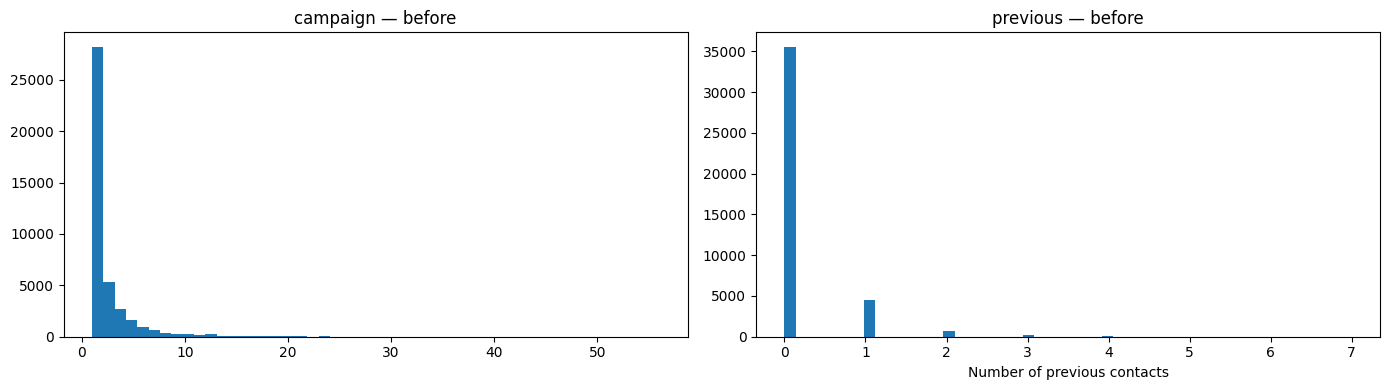

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Before
axes[0].hist(df_clean['campaign'], bins=50)
axes[0].set_title('campaign — before')

axes[1].hist(df_clean['previous'], bins=50)
axes[1].set_title('previous — before')
axes[1].set_xlabel('Number of previous contacts')

plt.tight_layout()

### Check for inconsistencies

In [43]:
# Strategy A — Remove rows where campaign > 10
df_clean_removed = df_clean[df_clean['campaign'] <= 10].copy()
print(f"Shape after removal: {df_clean_removed.shape} (removed {len(df_clean) - len(df_clean_removed)} rows)")

# Strategy B — Clip campaign at 10
df_clean_clipped = df_clean.copy()
df_clean_clipped['campaign'] = df_clean_clipped['campaign'].clip(upper=10)
print(f"Shape after clipping: {df_clean_clipped.shape} (all rows kept)")

Shape after removal: (40307, 21) (removed 869 rows)
Shape after clipping: (41176, 21) (all rows kept)


In [44]:
df_clean_removed[(df_clean_removed['previous'] == 0) & (df_clean_removed['poutcome'] != 'nonexistent')]
df_clean_clipped[(df_clean_clipped['previous'] == 0) & (df_clean_clipped['poutcome'] != 'nonexistent')]

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y


In [45]:
df_clean_removed[(df_clean_removed['previous'] > 0) & (df_clean_removed['poutcome'] == 'nonexistent')]
df_clean_clipped[(df_clean_clipped['previous'] > 0) & (df_clean_clipped['poutcome'] == 'nonexistent')]

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y


In [46]:
df_clean_removed[(df_clean_removed['age'] < 0)|(df_clean_removed['campaign'] < 0)|(df_clean_removed['previous'] < 0)|(df_clean_removed['pdays'] < 0)]
df_clean_clipped[(df_clean_clipped['age'] < 0)|(df_clean_clipped['campaign'] < 0)|(df_clean_clipped['previous'] < 0)|(df_clean_clipped['pdays'] < 0)]

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y


### Creating new variable

In [47]:
df_clean_removed['recent_contact'] = (df_clean_removed['pdays'] != 999).astype(int)
df_clean_clipped['recent_contact'] = (df_clean_clipped['pdays'] != 999).astype(int)

### Dropping Duration and pdays variables

In [48]:
df_clean_removed = df_clean_removed.drop(columns='pdays') 
df_clean_removed = df_clean_removed.drop(columns='duration')

df_clean_clipped = df_clean_clipped.drop(columns='pdays') 
df_clean_clipped = df_clean_clipped.drop(columns='duration')

## Preprocessing after split

### Train test split

In [49]:
X_removed = df_clean_removed.drop(columns='y') 
y_removed = df_clean_removed['y']
y_removed = y_removed.map({'yes': 1, 'no': 0})

X_clipped = df_clean_clipped.drop(columns='y')
y_clipped = df_clean_clipped['y']
y_clipped = y_clipped.map({'yes': 1, 'no': 0})

X_train_removed, X_test_removed, y_train_removed, y_test_removed = train_test_split(X_removed, y_removed, test_size=0.33, random_state=42, stratify=y_removed)
print(f'Shape after train-test split (removed outliers) - Train: {X_train_removed.shape}')
print(f'Shape after train-test split (removed outliers) - Test: {X_test_removed.shape}')

X_train_clipped, X_test_clipped, y_train_clipped, y_test_clipped = train_test_split(X_clipped, y_clipped, test_size=0.33, random_state=42, stratify=y_clipped)
print(f'Shape after train-test split (clipped outliers) - Train: {X_train_clipped.shape}')
print(f'Shape after train-test split (clipped outliers) - Test: {X_test_clipped.shape}')

Shape after train-test split (removed outliers) - Train: (27005, 19)
Shape after train-test split (removed outliers) - Test: (13302, 19)
Shape after train-test split (clipped outliers) - Train: (27587, 19)
Shape after train-test split (clipped outliers) - Test: (13589, 19)


### Imputing `unknown` catgories

In [50]:
numerical_columns = X_train_clipped.select_dtypes(include=['int64', 'float64']).columns
categorical_columns = X_train_clipped.select_dtypes(include=['object']).columns

X_train_encoded_removed = X_train_removed.copy()
X_test_encoded_removed = X_test_removed.copy()

encoders_removed = {}
for col in categorical_columns:
    le = LabelEncoder()
    le.fit(X_train_removed[col].dropna())
    encoders_removed[col] = le
    X_train_encoded_removed[col] = X_train_removed[col].map(lambda x: le.transform([x])[0] if pd.notna(x) else np.nan)
    X_test_encoded_removed[col] = X_test_removed[col].map(lambda x: le.transform([x])[0] if x in le.classes_ and pd.notna(x) else np.nan)

X_train_encoded_clipped = X_train_clipped.copy()
X_test_encoded_clipped = X_test_clipped.copy()

encoders_clipped = {}
for col in categorical_columns:
    le = LabelEncoder()
    le.fit(X_train_clipped[col].dropna())
    encoders_clipped[col] = le
    X_train_encoded_clipped[col] = X_train_clipped[col].map(lambda x: le.transform([x])[0] if pd.notna(x) else np.nan)
    X_test_encoded_clipped[col] = X_test_clipped[col].map(lambda x: le.transform([x])[0] if x in le.classes_ and pd.notna(x) else np.nan)

knn_imputer_removed = KNNImputer(n_neighbors=5)
X_train_imputed_removed = pd.DataFrame(knn_imputer_removed.fit_transform(X_train_encoded_removed), columns=X_train_removed.columns)
X_test_imputed_removed = pd.DataFrame(knn_imputer_removed.transform(X_test_encoded_removed), columns=X_test_removed.columns)

for col in categorical_columns:
    le = encoders_removed[col]
    X_train_imputed_removed[col] = le.inverse_transform(X_train_imputed_removed[col].round().astype(int))
    X_test_imputed_removed[col] = le.inverse_transform(X_test_imputed_removed[col].round().astype(int))

knn_imputer_clipped = KNNImputer(n_neighbors=5)
X_train_imputed_clipped = pd.DataFrame(knn_imputer_clipped.fit_transform(X_train_encoded_clipped), columns=X_train_clipped.columns)
X_test_imputed_clipped = pd.DataFrame(knn_imputer_clipped.transform(X_test_encoded_clipped), columns=X_test_clipped.columns)

for col in categorical_columns:
    le = encoders_clipped[col]
    X_train_imputed_clipped[col] = le.inverse_transform(X_train_imputed_clipped[col].round().astype(int))
    X_test_imputed_clipped[col] = le.inverse_transform(X_test_imputed_clipped[col].round().astype(int))

LabelEncoder()

LabelEncoder()

LabelEncoder()

LabelEncoder()

LabelEncoder()

LabelEncoder()

... (10 outputs left out)

LabelEncoder()

LabelEncoder()

LabelEncoder()

LabelEncoder()

### Scaling

In [51]:
scaler_removed = StandardScaler()
X_train_imputed_removed[numerical_columns] = scaler_removed.fit_transform(X_train_imputed_removed[numerical_columns])
X_test_imputed_removed[numerical_columns] = scaler_removed.transform(X_test_imputed_removed[numerical_columns])

scaler_clipped = StandardScaler()
X_train_imputed_clipped[numerical_columns] = scaler_clipped.fit_transform(X_train_imputed_clipped[numerical_columns])
X_test_imputed_clipped[numerical_columns] = scaler_clipped.transform(X_test_imputed_clipped[numerical_columns])

### Encoding categorical variables

In [52]:
X_train_imputed_removed = pd.get_dummies(X_train_imputed_removed, columns=categorical_columns)
X_test_imputed_removed = pd.get_dummies(X_test_imputed_removed, columns=categorical_columns)
X_test_imputed_removed = X_test_imputed_removed.reindex(columns=X_train_imputed_removed.columns, fill_value=0)

X_train_imputed_clipped = pd.get_dummies(X_train_imputed_clipped, columns=categorical_columns)
X_test_imputed_clipped = pd.get_dummies(X_test_imputed_clipped, columns=categorical_columns)
X_test_imputed_clipped = X_test_imputed_clipped.reindex(columns=X_train_imputed_clipped.columns, fill_value=0)

print(f'Shape after preprocessing (removed outliers) - Train: {X_train_imputed_removed.shape}')
print(f'Shape after preprocessing (removed outliers) - Test: {X_test_imputed_removed.shape}')

print(f'Shape after preprocessing (clipped outliers) - Train: {X_train_imputed_clipped.shape}')
print(f'Shape after preprocessing (clipped outliers) - Test: {X_test_imputed_clipped.shape}')

Shape after preprocessing (removed outliers) - Train: (27005, 56)
Shape after preprocessing (removed outliers) - Test: (13302, 56)
Shape after preprocessing (clipped outliers) - Train: (27587, 56)
Shape after preprocessing (clipped outliers) - Test: (13589, 56)


### Auxiliary functions

In [53]:
results_df = pd.DataFrame(columns=['Model', 'F1-score (cv)', 'Precision (cv)','Recall (cv)', 'Accuracy (cv)', 'ROC-AUC', 'AUPR', 'time'])

def confusion(true, pred):
    """
    Function for pretty printing confusion matrices
    """
    pred = pd.Series(pred)
    true = pd.Series(true)

    true.name = 'target'
    pred.name = 'predicted'
    cm = pd.crosstab(true.reset_index(drop=True), pred.reset_index(drop=True))
    cm = cm[cm.index]
    return cm

def add_result_cv(results_df, model_name, cv_results):

    temps_total = cv_results['fit_time'].sum() + cv_results['score_time'].sum()

    row = {
        'Model': model_name,
        'AUPR': cv_results['test_average_precision'].mean(),
        'F1-score (cv)': cv_results['test_f1_macro'].mean(),
        'Precision (cv)': cv_results['test_precision_macro'].mean(),
        'Recall (cv)': cv_results['test_recall_macro'].mean(),
        'Accuracy (cv)': cv_results['test_accuracy'].mean(),
        'ROC-AUC': cv_results['test_roc_auc'].mean(),
        'time': temps_total
    }

    return pd.concat([results_df, pd.DataFrame([row])], ignore_index=True)

aupr_scorer = make_scorer(average_precision_score, response_method='predict_proba')

scoring = {
    'accuracy':          'accuracy',
    'f1_macro':          'f1_macro',
    'precision_macro':   'precision_macro',
    'recall_macro':      'recall_macro',
    'roc_auc':           'roc_auc',
    'average_precision': aupr_scorer,
}

# Unsupervised analysis

Text(0.5, 0, 'Number of Components')

Text(0, 0.5, 'Cumulative Explained Variance')

Text(0.5, 1.0, 'PCA — Cumulative Explained Variance')

<BarContainer object of 20 artists>

Text(0.5, 0, 'Principal Component')

Text(0, 0.5, 'Explained Variance Ratio')

Text(0.5, 1.0, 'PCA — Scree Plot (first 20 components)')

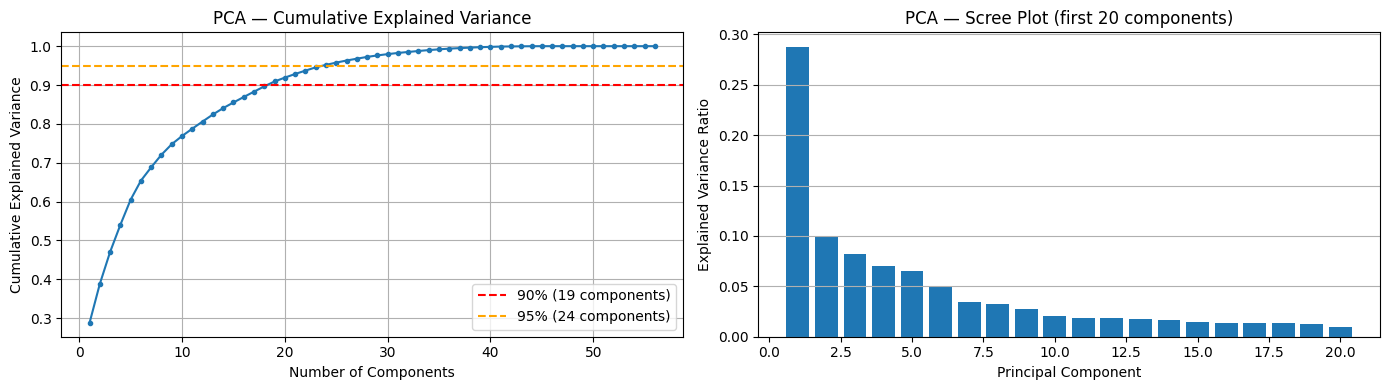

Components needed for 90% variance: 19
Components needed for 95% variance: 24
Total features: 56


Text(0.5, 0, 'Number of Clusters (k)')

Text(0, 0.5, 'Inertia (WCSS)')

Text(0.5, 1.0, 'K-Means — Elbow Method')

Text(0.5, 0, 'Number of Clusters (k)')

Text(0, 0.5, 'Silhouette Score')

Text(0.5, 1.0, 'K-Means — Silhouette Score')

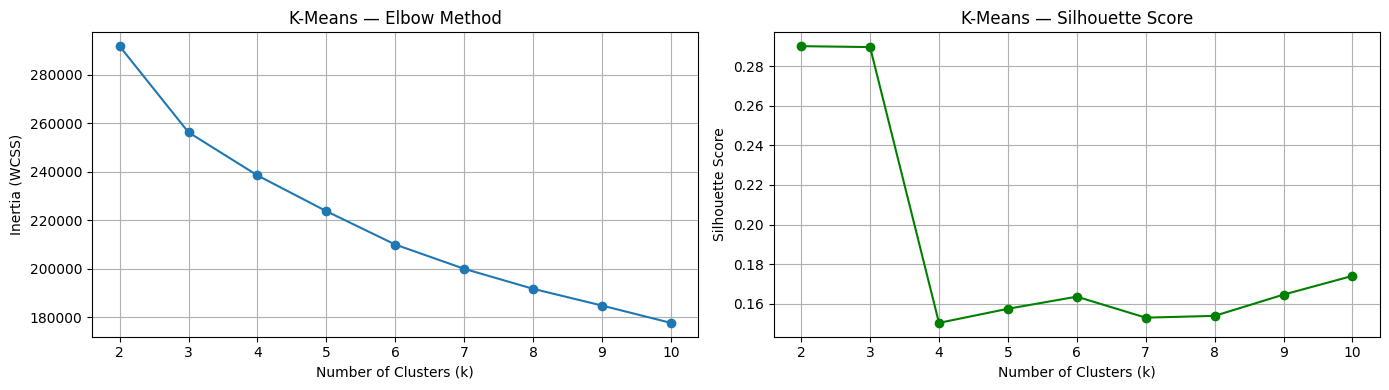

Best k by silhouette: 2


,"n_components n_components: int, default=1The number of mixture components.",2
,"covariance_type covariance_type: {'full', 'tied', 'diag', 'spherical'}, default='full'String describing the type of covariance parameters to use.Must be one of:- 'full': each component has its own general covariance matrix.- 'tied': all components share the same general covariance matrix.- 'diag': each component has its own diagonal covariance matrix.- 'spherical': each component has its own single variance.For an example of using `covariance_type`, refer to:ref:`sphx_glr_auto_examples_mixture_plot_gmm_selection.py`.",'full'
,"tol tol: float, default=1e-3The convergence threshold. EM iterations will stop when thelower bound average gain is below this threshold.",0.001
,"reg_covar reg_covar: float, default=1e-6Non-negative regularization added to the diagonal of covariance.Allows to assure that the covariance matrices are all positive.",1e-06
,"max_iter max_iter: int, default=100The number of EM iterations to perform.",100
,"n_init n_init: int, default=1The number of initializations to perform. The best results are kept.",3
,"init_params init_params: {'kmeans', 'k-means++', 'random', 'random_from_data'}, default='kmeans'The method used to initialize the weights, the means and theprecisions.String must be one of:- 'kmeans' : responsibilities are initialized using kmeans.- 'k-means++' : use the k-means++ method to initialize.- 'random' : responsibilities are initialized randomly.- 'random_from_data' : initial means are randomly selected data points... versionchanged:: v1.1 `init_params` now accepts 'random_from_data' and 'k-means++' as initialization methods.",'kmeans'
,"weights_init weights_init: array-like of shape (n_components, ), default=NoneThe user-provided initial weights.If it is None, weights are initialized using the `init_params` method.",None
,"means_init means_init: array-like of shape (n_components, n_features), default=NoneThe user-provided initial means,If it is None, means are initialized using the `init_params` method.",None
,"precisions_init precisions_init: array-like, default=NoneThe user-provided initial precisions (inverse of the covariancematrices).If it is None, precisions are initialized using the 'init_params'method.The shape depends on 'covariance_type':: (n_components,) if 'spherical', (n_features, n_features) if 'tied', (n_components, n_features) if 'diag', (n_components, n_features, n_features) if 'full'",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to the method chosen to initialize theparameters (see `init_params`).In addition, it controls the generation of random samples from thefitted distribution (see the method `sample`).Pass an int for reproducible output across multiple function calls.See :term:`Glossary `.",42


,"n_components n_components: int, default=1The number of mixture components.",3
,"covariance_type covariance_type: {'full', 'tied', 'diag', 'spherical'}, default='full'String describing the type of covariance parameters to use.Must be one of:- 'full': each component has its own general covariance matrix.- 'tied': all components share the same general covariance matrix.- 'diag': each component has its own diagonal covariance matrix.- 'spherical': each component has its own single variance.For an example of using `covariance_type`, refer to:ref:`sphx_glr_auto_examples_mixture_plot_gmm_selection.py`.",'full'
,"tol tol: float, default=1e-3The convergence threshold. EM iterations will stop when thelower bound average gain is below this threshold.",0.001
,"reg_covar reg_covar: float, default=1e-6Non-negative regularization added to the diagonal of covariance.Allows to assure that the covariance matrices are all positive.",1e-06
,"max_iter max_iter: int, default=100The number of EM iterations to perform.",100
,"n_init n_init: int, default=1The number of initializations to perform. The best results are kept.",3
,"init_params init_params: {'kmeans', 'k-means++', 'random', 'random_from_data'}, default='kmeans'The method used to initialize the weights, the means and theprecisions.String must be one of:- 'kmeans' : responsibilities are initialized using kmeans.- 'k-means++' : use the k-means++ method to initialize.- 'random' : responsibilities are initialized randomly.- 'random_from_data' : initial means are randomly selected data points... versionchanged:: v1.1 `init_params` now accepts 'random_from_data' and 'k-means++' as initialization methods.",'kmeans'
,"weights_init weights_init: array-like of shape (n_components, ), default=NoneThe user-provided initial weights.If it is None, weights are initialized using the `init_params` method.",None
,"means_init means_init: array-like of shape (n_components, n_features), default=NoneThe user-provided initial means,If it is None, means are initialized using the `init_params` method.",None
,"precisions_init precisions_init: array-like, default=NoneThe user-provided initial precisions (inverse of the covariancematrices).If it is None, precisions are initialized using the 'init_params'method.The shape depends on 'covariance_type':: (n_components,) if 'spherical', (n_features, n_features) if 'tied', (n_components, n_features) if 'diag', (n_components, n_features, n_features) if 'full'",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to the method chosen to initialize theparameters (see `init_params`).In addition, it controls the generation of random samples from thefitted distribution (see the method `sample`).Pass an int for reproducible output across multiple function calls.See :term:`Glossary `.",42


,"n_components n_components: int, default=1The number of mixture components.",4
,"covariance_type covariance_type: {'full', 'tied', 'diag', 'spherical'}, default='full'String describing the type of covariance parameters to use.Must be one of:- 'full': each component has its own general covariance matrix.- 'tied': all components share the same general covariance matrix.- 'diag': each component has its own diagonal covariance matrix.- 'spherical': each component has its own single variance.For an example of using `covariance_type`, refer to:ref:`sphx_glr_auto_examples_mixture_plot_gmm_selection.py`.",'full'
,"tol tol: float, default=1e-3The convergence threshold. EM iterations will stop when thelower bound average gain is below this threshold.",0.001
,"reg_covar reg_covar: float, default=1e-6Non-negative regularization added to the diagonal of covariance.Allows to assure that the covariance matrices are all positive.",1e-06
,"max_iter max_iter: int, default=100The number of EM iterations to perform.",100
,"n_init n_init: int, default=1The number of initializations to perform. The best results are kept.",3
,"init_params init_params: {'kmeans', 'k-means++', 'random', 'random_from_data'}, default='kmeans'The method used to initialize the weights, the means and theprecisions.String must be one of:- 'kmeans' : responsibilities are initialized using kmeans.- 'k-means++' : use the k-means++ method to initialize.- 'random' : responsibilities are initialized randomly.- 'random_from_data' : initial means are randomly selected data points... versionchanged:: v1.1 `init_params` now accepts 'random_from_data' and 'k-means++' as initialization methods.",'kmeans'
,"weights_init weights_init: array-like of shape (n_components, ), default=NoneThe user-provided initial weights.If it is None, weights are initialized using the `init_params` method.",None
,"means_init means_init: array-like of shape (n_components, n_features), default=NoneThe user-provided initial means,If it is None, means are initialized using the `init_params` method.",None
,"precisions_init precisions_init: array-like, default=NoneThe user-provided initial precisions (inverse of the covariancematrices).If it is None, precisions are initialized using the 'init_params'method.The shape depends on 'covariance_type':: (n_components,) if 'spherical', (n_features, n_features) if 'tied', (n_components, n_features) if 'diag', (n_components, n_features, n_features) if 'full'",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to the method chosen to initialize theparameters (see `init_params`).In addition, it controls the generation of random samples from thefitted distribution (see the method `sample`).Pass an int for reproducible output across multiple function calls.See :term:`Glossary `.",42


,"n_components n_components: int, default=1The number of mixture components.",5
,"covariance_type covariance_type: {'full', 'tied', 'diag', 'spherical'}, default='full'String describing the type of covariance parameters to use.Must be one of:- 'full': each component has its own general covariance matrix.- 'tied': all components share the same general covariance matrix.- 'diag': each component has its own diagonal covariance matrix.- 'spherical': each component has its own single variance.For an example of using `covariance_type`, refer to:ref:`sphx_glr_auto_examples_mixture_plot_gmm_selection.py`.",'full'
,"tol tol: float, default=1e-3The convergence threshold. EM iterations will stop when thelower bound average gain is below this threshold.",0.001
,"reg_covar reg_covar: float, default=1e-6Non-negative regularization added to the diagonal of covariance.Allows to assure that the covariance matrices are all positive.",1e-06
,"max_iter max_iter: int, default=100The number of EM iterations to perform.",100
,"n_init n_init: int, default=1The number of initializations to perform. The best results are kept.",3
,"init_params init_params: {'kmeans', 'k-means++', 'random', 'random_from_data'}, default='kmeans'The method used to initialize the weights, the means and theprecisions.String must be one of:- 'kmeans' : responsibilities are initialized using kmeans.- 'k-means++' : use the k-means++ method to initialize.- 'random' : responsibilities are initialized randomly.- 'random_from_data' : initial means are randomly selected data points... versionchanged:: v1.1 `init_params` now accepts 'random_from_data' and 'k-means++' as initialization methods.",'kmeans'
,"weights_init weights_init: array-like of shape (n_components, ), default=NoneThe user-provided initial weights.If it is None, weights are initialized using the `init_params` method.",None
,"means_init means_init: array-like of shape (n_components, n_features), default=NoneThe user-provided initial means,If it is None, means are initialized using the `init_params` method.",None
,"precisions_init precisions_init: array-like, default=NoneThe user-provided initial precisions (inverse of the covariancematrices).If it is None, precisions are initialized using the 'init_params'method.The shape depends on 'covariance_type':: (n_components,) if 'spherical', (n_features, n_features) if 'tied', (n_components, n_features) if 'diag', (n_components, n_features, n_features) if 'full'",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to the method chosen to initialize theparameters (see `init_params`).In addition, it controls the generation of random samples from thefitted distribution (see the method `sample`).Pass an int for reproducible output across multiple function calls.See :term:`Glossary `.",42


,"n_components n_components: int, default=1The number of mixture components.",6
,"covariance_type covariance_type: {'full', 'tied', 'diag', 'spherical'}, default='full'String describing the type of covariance parameters to use.Must be one of:- 'full': each component has its own general covariance matrix.- 'tied': all components share the same general covariance matrix.- 'diag': each component has its own diagonal covariance matrix.- 'spherical': each component has its own single variance.For an example of using `covariance_type`, refer to:ref:`sphx_glr_auto_examples_mixture_plot_gmm_selection.py`.",'full'
,"tol tol: float, default=1e-3The convergence threshold. EM iterations will stop when thelower bound average gain is below this threshold.",0.001
,"reg_covar reg_covar: float, default=1e-6Non-negative regularization added to the diagonal of covariance.Allows to assure that the covariance matrices are all positive.",1e-06
,"max_iter max_iter: int, default=100The number of EM iterations to perform.",100
,"n_init n_init: int, default=1The number of initializations to perform. The best results are kept.",3
,"init_params init_params: {'kmeans', 'k-means++', 'random', 'random_from_data'}, default='kmeans'The method used to initialize the weights, the means and theprecisions.String must be one of:- 'kmeans' : responsibilities are initialized using kmeans.- 'k-means++' : use the k-means++ method to initialize.- 'random' : responsibilities are initialized randomly.- 'random_from_data' : initial means are randomly selected data points... versionchanged:: v1.1 `init_params` now accepts 'random_from_data' and 'k-means++' as initialization methods.",'kmeans'
,"weights_init weights_init: array-like of shape (n_components, ), default=NoneThe user-provided initial weights.If it is None, weights are initialized using the `init_params` method.",None
,"means_init means_init: array-like of shape (n_components, n_features), default=NoneThe user-provided initial means,If it is None, means are initialized using the `init_params` method.",None
,"precisions_init precisions_init: array-like, default=NoneThe user-provided initial precisions (inverse of the covariancematrices).If it is None, precisions are initialized using the 'init_params'method.The shape depends on 'covariance_type':: (n_components,) if 'spherical', (n_features, n_features) if 'tied', (n_components, n_features) if 'diag', (n_components, n_features, n_features) if 'full'",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to the method chosen to initialize theparameters (see `init_params`).In addition, it controls the generation of random samples from thefitted distribution (see the method `sample`).Pass an int for reproducible output across multiple function calls.See :term:`Glossary `.",42


... (4 outputs left out)

<Figure size 700x400 with 0 Axes>

Text(0.5, 0, 'Number of Components')

Text(0, 0.5, 'BIC')

Text(0.5, 1.0, 'GMM — BIC Score (lower is better)')

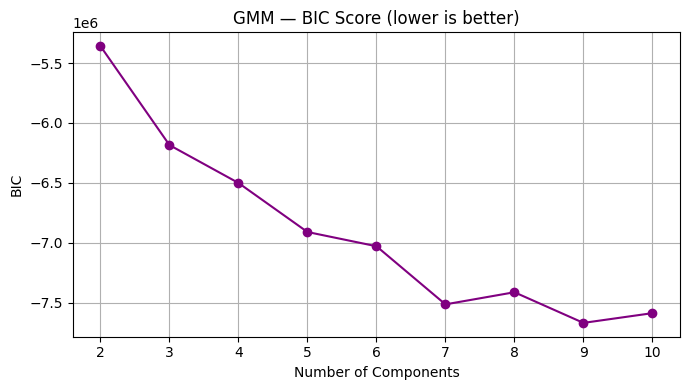

Best GMM components by BIC: 9


,"n_components n_components: int, default=1The number of mixture components.",9
,"covariance_type covariance_type: {'full', 'tied', 'diag', 'spherical'}, default='full'String describing the type of covariance parameters to use.Must be one of:- 'full': each component has its own general covariance matrix.- 'tied': all components share the same general covariance matrix.- 'diag': each component has its own diagonal covariance matrix.- 'spherical': each component has its own single variance.For an example of using `covariance_type`, refer to:ref:`sphx_glr_auto_examples_mixture_plot_gmm_selection.py`.",'full'
,"tol tol: float, default=1e-3The convergence threshold. EM iterations will stop when thelower bound average gain is below this threshold.",0.001
,"reg_covar reg_covar: float, default=1e-6Non-negative regularization added to the diagonal of covariance.Allows to assure that the covariance matrices are all positive.",1e-06
,"max_iter max_iter: int, default=100The number of EM iterations to perform.",100
,"n_init n_init: int, default=1The number of initializations to perform. The best results are kept.",3
,"init_params init_params: {'kmeans', 'k-means++', 'random', 'random_from_data'}, default='kmeans'The method used to initialize the weights, the means and theprecisions.String must be one of:- 'kmeans' : responsibilities are initialized using kmeans.- 'k-means++' : use the k-means++ method to initialize.- 'random' : responsibilities are initialized randomly.- 'random_from_data' : initial means are randomly selected data points... versionchanged:: v1.1 `init_params` now accepts 'random_from_data' and 'k-means++' as initialization methods.",'kmeans'
,"weights_init weights_init: array-like of shape (n_components, ), default=NoneThe user-provided initial weights.If it is None, weights are initialized using the `init_params` method.",None
,"means_init means_init: array-like of shape (n_components, n_features), default=NoneThe user-provided initial means,If it is None, means are initialized using the `init_params` method.",None
,"precisions_init precisions_init: array-like, default=NoneThe user-provided initial precisions (inverse of the covariancematrices).If it is None, precisions are initialized using the 'init_params'method.The shape depends on 'covariance_type':: (n_components,) if 'spherical', (n_features, n_features) if 'tied', (n_components, n_features) if 'diag', (n_components, n_features, n_features) if 'full'",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to the method chosen to initialize theparameters (see `init_params`).In addition, it controls the generation of random samples from thefitted distribution (see the method `sample`).Pass an int for reproducible output across multiple function calls.See :term:`Glossary `.",42


Text(0.5, 0, 'Cluster')

Text(0, 0.5, 'Subscription Rate')

Text(0.5, 1.0, 'K-Means (k=2) — Subscription Rate per Cluster')

Text(0.0, 0.24572238740226848, 'n=9081')

... (9 outputs left out)

Text(5.0, 0.059028436018957346, 'n=1055')

Text(6.0, 0.0577073732718894, 'n=3472')

Text(7.0, 0.04601161995898838, 'n=2926')

Text(8.0, 0.036848459616985844, 'n=4804')

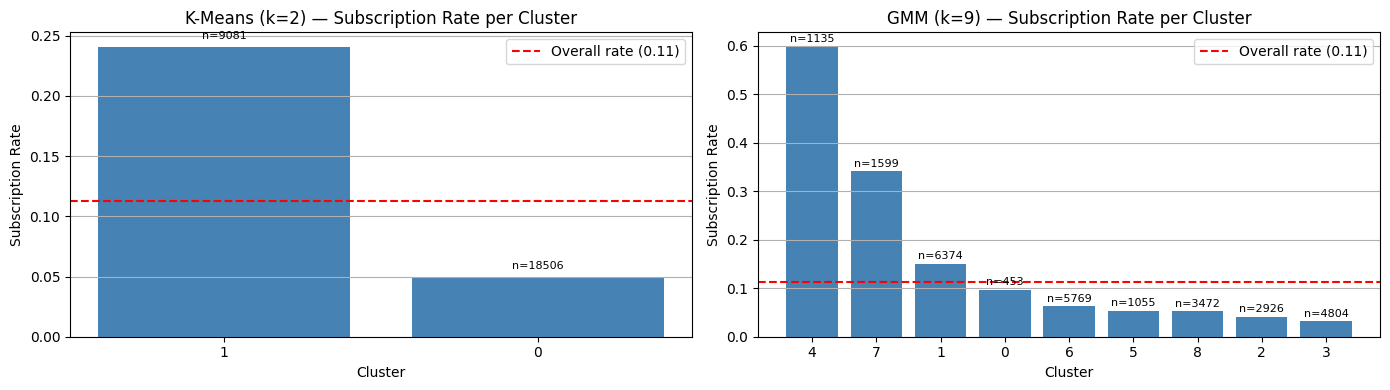


K-Means cluster summary:
         subscription_rate   size
cluster                          
0                    0.050  18506
1                    0.241   9081

GMM cluster summary:
         subscription_rate  size
cluster                         
0                    0.097   453
1                    0.151  6374
2                    0.041  2926
3                    0.032  4804
4                    0.598  1135
5                    0.054  1055
6                    0.063  5769
7                    0.342  1599
8                    0.053  3472


In [ ]:
X_unsup = X_train_imputed_clipped.copy().reset_index(drop=True)
y_unsup = y_train_clipped.copy().reset_index(drop=True)

# 1. PCA Explained Variance
pca_full = PCA().fit(X_unsup)
cumvar = np.cumsum(pca_full.explained_variance_ratio_)
n_90 = np.searchsorted(cumvar, 0.90) + 1
n_95 = np.searchsorted(cumvar, 0.95) + 1
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(range(1, len(cumvar) + 1), cumvar, marker='o', markersize=3)
axes[0].axhline(0.90, color='red',    linestyle='--', label=f'90% ({n_90} components)')
axes[0].axhline(0.95, color='orange', linestyle='--', label=f'95% ({n_95} components)')
axes[0].set_xlabel('Number of Components')
axes[0].set_ylabel('Cumulative Explained Variance')
axes[0].set_title('PCA — Cumulative Explained Variance')
axes[0].legend()
axes[0].grid(True)
axes[1].bar(range(1, min(21, len(pca_full.explained_variance_ratio_))),
            pca_full.explained_variance_ratio_[:20])
axes[1].set_xlabel('Principal Component')
axes[1].set_ylabel('Explained Variance Ratio')
axes[1].set_title('PCA — Scree Plot (first 20 components)')
axes[1].grid(True, axis='y')
plt.tight_layout()
plt.show()
print(f"Components needed for 90% variance: {n_90}")
print(f"Components needed for 95% variance: {n_95}")
print(f"Total features: {X_unsup.shape[1]}")

# 2. K-Means: Elbow + Silhouette
K_range = range(2, 11)
inertias   = []
sil_scores = []
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_unsup)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_unsup, labels, sample_size=5000, random_state=42))
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(K_range, inertias, marker='o')
axes[0].set_xlabel('Number of Clusters (k)')
axes[0].set_ylabel('Inertia (WCSS)')
axes[0].set_title('K-Means — Elbow Method')
axes[0].grid(True)
axes[1].plot(K_range, sil_scores, marker='o', color='green')
axes[1].set_xlabel('Number of Clusters (k)')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_title('K-Means — Silhouette Score')
axes[1].grid(True)
plt.tight_layout()
plt.show()
best_k = K_range[np.argmax(sil_scores)]
print(f"Best k by silhouette: {best_k}")

# 3. GMM: BIC to select number of components
bic_scores = []
gmm_range  = range(2, 11)
for k in gmm_range:
    gmm = GaussianMixture(n_components=k, random_state=42, n_init=3)
    gmm.fit(X_unsup)
    bic_scores.append(gmm.bic(X_unsup))
plt.figure(figsize=(7, 4))
plt.plot(gmm_range, bic_scores, marker='o', color='purple')
plt.xlabel('Number of Components')
plt.ylabel('BIC')
plt.title('GMM — BIC Score (lower is better)')
plt.grid(True)
plt.tight_layout()
plt.show()
best_k_gmm = gmm_range[np.argmin(bic_scores)]
print(f"Best GMM components by BIC: {best_k_gmm}")

# 4. Cluster alignment with target
km_final = KMeans(n_clusters=best_k, random_state=42, n_init=10)
km_labels = km_final.fit_predict(X_unsup)

gmm_final = GaussianMixture(n_components=best_k_gmm, random_state=42, n_init=3)
gmm_final.fit(X_unsup)
gmm_labels = gmm_final.predict(X_unsup)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, labels, title in [
    (axes[0], km_labels,  f'K-Means (k={best_k}) — Subscription Rate per Cluster'),
    (axes[1], gmm_labels, f'GMM (k={best_k_gmm}) — Subscription Rate per Cluster'),
]:
    cluster_df = pd.DataFrame({'cluster': labels, 'target': y_unsup.values})
    rates = cluster_df.groupby('cluster')['target'].mean().sort_values(ascending=False)
    counts = cluster_df.groupby('cluster')['target'].count().reindex(rates.index)
    bars = ax.bar(rates.index.astype(str), rates.values, color='steelblue')
    ax.axhline(y_unsup.mean(), color='red', linestyle='--', label=f'Overall rate ({y_unsup.mean():.2f})')
    ax.set_xlabel('Cluster')
    ax.set_ylabel('Subscription Rate')
    ax.set_title(title)
    ax.legend()
    ax.grid(True, axis='y')

    for bar, (_, count) in zip(bars, counts.items()):
        ax.text(bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 0.005,
                f'n={count}', ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.show()

print("\nK-Means cluster summary:")
km_summary = pd.DataFrame({'cluster': km_labels, 'target': y_unsup.values}).groupby('cluster')['target'].agg(['mean', 'count']).rename(columns={'mean': 'subscription_rate', 'count': 'size'})
print(km_summary.round(3))

print("\nGMM cluster summary:")
gmm_summary = pd.DataFrame({'cluster': gmm_labels, 'target': y_unsup.values}).groupby('cluster')['target'].agg(['mean', 'count']).rename(columns={'mean': 'subscription_rate', 'count': 'size'})
print(gmm_summary.round(3))

# Feature selection or extraction

## Variance and correlation filtering

**Removed Dataset**

In [54]:
var_selector_removed = VarianceThreshold(threshold=0.01)
var_selector_removed.fit(X_train_imputed_removed)#(X_train_res_removed)

removed_var_removed = X_train_imputed_removed.columns[~var_selector_removed.get_support()].tolist()

print(f"Shape after variance threshold (removed outliers):")
print(f"Removed features: {len(removed_var_removed)}")
print(removed_var_removed)

X_train_v_removed = pd.DataFrame(var_selector_removed.transform(X_train_imputed_removed),columns=X_train_imputed_removed.columns[var_selector_removed.get_support()])

X_test_v_removed = pd.DataFrame(var_selector_removed.transform(X_test_imputed_removed),columns=X_train_v_removed.columns)

corr_matrix_removed = X_train_v_removed.corr().abs()

upper_removed = corr_matrix_removed.where(np.triu(np.ones(corr_matrix_removed.shape), k=1).astype(bool))

to_drop_removed = [col for col in upper_removed.columns if any(upper_removed[col] > 0.90)]

print(f"\nShape after correlation filtering (removed outliers):")
print(f"Removed features: {len(to_drop_removed)}")
print(to_drop_removed)

print("\nCorrelation pairs that triggered removal:")
for col in to_drop_removed:
    correlated_with = upper_removed[col][upper_removed[col] > 0.90]
    for other_col, corr_val in correlated_with.items():
        print(f"  {col} <-> {other_col}: {corr_val:.3f}")

X_train_selected_removed = X_train_v_removed.drop(columns=to_drop_removed)

X_test_filtered_removed = X_test_v_removed.drop(columns=to_drop_removed)

print(f"\nFinal shape after feature selection (removed outliers):")
print(X_train_selected_removed.shape)

,"threshold threshold: float, default=0Features with a training-set variance lower than this threshold willbe removed. The default is to keep all features with non-zero variance,i.e. remove the features that have the same value in all samples.",0.01


Shape after variance threshold (removed outliers):
Removed features: 4
['education_illiterate', 'default_no', 'default_yes', 'month_dec']

Shape after correlation filtering (removed outliers):
Removed features: 6
['euribor3m', 'nr.employed', 'housing_yes', 'loan_yes', 'contact_telephone', 'poutcome_success']

Correlation pairs that triggered removal:
  euribor3m <-> emp.var.rate: 0.972
  nr.employed <-> emp.var.rate: 0.906
  nr.employed <-> euribor3m: 0.945
  housing_yes <-> housing_no: 1.000
  loan_yes <-> loan_no: 1.000
  contact_telephone <-> contact_cellular: 1.000
  poutcome_success <-> recent_contact: 0.945

Final shape after feature selection (removed outliers):
(27005, 46)


**Clipped Dataset**

In [55]:
var_selector_clipped = VarianceThreshold(threshold=0.01)
var_selector_clipped.fit(X_train_imputed_clipped)#(X_train_res_clipped)

removed_var_clipped = X_train_imputed_clipped.columns[~var_selector_clipped.get_support()].tolist()

print(f"\nShape after variance threshold (clipped outliers):")
print(f"Removed features: {len(removed_var_clipped)}")
print(removed_var_clipped)

X_train_v_clipped = pd.DataFrame(var_selector_clipped.transform(X_train_imputed_clipped),columns=X_train_imputed_clipped.columns[var_selector_clipped.get_support()])

X_test_v_clipped = pd.DataFrame(var_selector_clipped.transform(X_test_imputed_clipped),columns=X_train_v_clipped.columns)

corr_matrix_clipped = X_train_v_clipped.corr().abs()

upper_clipped = corr_matrix_clipped.where(np.triu(np.ones(corr_matrix_clipped.shape), k=1).astype(bool)
)

to_drop_clipped = [col for col in upper_clipped.columns if any(upper_clipped[col] > 0.90)]

print(f"\nShape after correlation filtering (clipped outliers):")
print(f"Removed features: {len(to_drop_clipped)}")
print(to_drop_clipped)

print("\nCorrelation pairs that triggered removal:")
for col in to_drop_clipped:
    correlated_with = upper_removed[col][upper_removed[col] > 0.90]
    for other_col, corr_val in correlated_with.items():
        print(f"  {col} <-> {other_col}: {corr_val:.3f}")

X_train_selected_clipped = X_train_v_clipped.drop(columns=to_drop_clipped)

X_test_filtered_clipped = X_test_v_clipped.drop(columns=to_drop_clipped)

print(f"\nFinal shape after feature selection (clipped outliers):")
print(X_train_selected_clipped.shape)

,"threshold threshold: float, default=0Features with a training-set variance lower than this threshold willbe removed. The default is to keep all features with non-zero variance,i.e. remove the features that have the same value in all samples.",0.01



Shape after variance threshold (clipped outliers):
Removed features: 3
['default_no', 'default_yes', 'month_dec']

Shape after correlation filtering (clipped outliers):
Removed features: 6
['euribor3m', 'nr.employed', 'housing_yes', 'loan_yes', 'contact_telephone', 'poutcome_success']

Correlation pairs that triggered removal:
  euribor3m <-> emp.var.rate: 0.972
  nr.employed <-> emp.var.rate: 0.906
  nr.employed <-> euribor3m: 0.945
  housing_yes <-> housing_no: 1.000
  loan_yes <-> loan_no: 1.000
  contact_telephone <-> contact_cellular: 1.000
  poutcome_success <-> recent_contact: 0.945

Final shape after feature selection (clipped outliers):
(27587, 47)


## PCA 

**Removed Dataset**

In [56]:
pca_removed = PCA().fit(X_train_selected_removed)

n_components_removed =(pca_removed.explained_variance_ratio_.cumsum() <= 0.9).sum()

print(f'Number of components for 90% explained variance: {n_components_removed}')

pca_removed = PCA(n_components=n_components_removed)
pca_removed.fit(X_train_selected_removed)

X_train_pca_removed = pca_removed.transform(X_train_selected_removed)
X_test_pca_removed = pca_removed.transform(X_test_filtered_removed)

print(f'Shape after PCA (removed outliers) - Train: {X_train_pca_removed.shape}')
print(f'Shape after PCA (removed outliers) - Test: {X_test_pca_removed.shape}')

Number of components for 90% explained variance: 19


,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",np.int64(19)
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the number of components to extract is lower than 80% of the smallest dimension of the data, then the more efficient ""randomized"" method is selected. Otherwise the exact ""full"" SVD is computed and optionally truncated afterwards.""full"" : Run exact full SVD calling the standard LAPACK solver via `scipy.linalg.svd` and select the components by postprocessing""covariance_eigh"" : Precompute the covariance matrix (on centered data), run a classical eigenvalue decomposition on the covariance matrix typically using LAPACK and select the components by postprocessing. This solver is very efficient for n_samples >> n_features and small n_features. It is, however, not tractable otherwise for large n_features (large memory footprint required to materialize the covariance matrix). Also note that compared to the ""full"" solver, this solver effectively doubles the condition number and is therefore less numerical stable (e.g. on input data with a large range of singular values).""arpack"" : Run SVD truncated to `n_components` calling ARPACK solver via `scipy.sparse.linalg.svds`. It requires strictly `0 < n_components < min(X.shape)`""randomized"" : Run randomized SVD by the method of Halko et al... versionadded:: 0.18.0.. versionchanged:: 1.5 Added the 'covariance_eigh' solver.",'auto'
,"tol tol: float, default=0.0Tolerance for singular values computed by svd_solver == 'arpack'.Must be of range [0.0, infinity)... versionadded:: 0.18.0",0.0
,"iterated_power iterated_power: int or 'auto', default='auto'Number of iterations for the power method computed bysvd_solver == 'randomized'.Must be of range [0, infinity)... versionadded:: 0.18.0",'auto'
,"n_oversamples n_oversamples: int, default=10This parameter is only relevant when `svd_solver=""randomized""`.It corresponds to the additional number of random vectors to sample therange of `X` so as to ensure proper conditioning. See:func:`~sklearn.utils.extmath.randomized_svd` for more details... versionadded:: 1.1",10
,"power_iteration_normalizer power_iteration_normalizer: {'auto', 'QR', 'LU', 'none'}, default='auto'Power iteration normalizer for rand

Shape after PCA (removed outliers) - Train: (27005, 19)
Shape after PCA (removed outliers) - Test: (13302, 19)


**Clipped Dataset**

In [57]:
pca_clipped = PCA().fit(X_train_selected_clipped)

n_components_clipped =(pca_clipped.explained_variance_ratio_.cumsum() <= 0.9).sum()

print()
print(f'Number of components for 90% explained variance: {n_components_clipped}')

pca_clipped = PCA(n_components=n_components_clipped)
pca_clipped.fit(X_train_selected_clipped)

X_train_pca_clipped = pca_clipped .transform(X_train_selected_clipped)
X_test_pca_clipped = pca_clipped.transform(X_test_filtered_clipped)

print(f'Shape after PCA (clipped outliers) - Train: {X_train_pca_clipped.shape}')
print(f'Shape after PCA (clipped outliers) - Test: {X_test_pca_clipped.shape}')


Number of components for 90% explained variance: 19


,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",np.int64(19)
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the number of components to extract is lower than 80% of the smallest dimension of the data, then the more efficient ""randomized"" method is selected. Otherwise the exact ""full"" SVD is computed and optionally truncated afterwards.""full"" : Run exact full SVD calling the standard LAPACK solver via `scipy.linalg.svd` and select the components by postprocessing""covariance_eigh"" : Precompute the covariance matrix (on centered data), run a classical eigenvalue decomposition on the covariance matrix typically using LAPACK and select the components by postprocessing. This solver is very efficient for n_samples >> n_features and small n_features. It is, however, not tractable otherwise for large n_features (large memory footprint required to materialize the covariance matrix). Also note that compared to the ""full"" solver, this solver effectively doubles the condition number and is therefore less numerical stable (e.g. on input data with a large range of singular values).""arpack"" : Run SVD truncated to `n_components` calling ARPACK solver via `scipy.sparse.linalg.svds`. It requires strictly `0 < n_components < min(X.shape)`""randomized"" : Run randomized SVD by the method of Halko et al... versionadded:: 0.18.0.. versionchanged:: 1.5 Added the 'covariance_eigh' solver.",'auto'
,"tol tol: float, default=0.0Tolerance for singular values computed by svd_solver == 'arpack'.Must be of range [0.0, infinity)... versionadded:: 0.18.0",0.0
,"iterated_power iterated_power: int or 'auto', default='auto'Number of iterations for the power method computed bysvd_solver == 'randomized'.Must be of range [0, infinity)... versionadded:: 0.18.0",'auto'
,"n_oversamples n_oversamples: int, default=10This parameter is only relevant when `svd_solver=""randomized""`.It corresponds to the additional number of random vectors to sample therange of `X` so as to ensure proper conditioning. See:func:`~sklearn.utils.extmath.randomized_svd` for more details... versionadded:: 1.1",10
,"power_iteration_normalizer power_iteration_normalizer: {'auto', 'QR', 'LU', 'none'}, default='auto'Power iteration normalizer for rand

Shape after PCA (clipped outliers) - Train: (27587, 19)
Shape after PCA (clipped outliers) - Test: (13589, 19)


# Model comparison

## Baseline

In [ ]:
for name, X, y in [
    ('Dummy Classifier (Clipped)',     X_train_selected_clipped,     y_train_clipped),
    ('Dummy Classifier (Removed)',     X_train_selected_removed,     y_train_removed),
    ('Dummy Classifier (Clipped PCA)', X_train_pca_clipped, y_train_clipped),
    ('Dummy Classifier (Removed PCA)', X_train_pca_removed, y_train_removed),
]:
    dummy_pipe = ImbPipeline([
        ('smote', SMOTE(random_state=42)),
        ('clf',   DummyClassifier(strategy='most_frequent', random_state=42))
    ])
    cv = cross_validate(dummy_pipe, X, y, cv=5, scoring=scoring)
    results_df = add_result_cv(results_df, name, cv)

C:\Users\usuario\AppData\Roaming\Python\Python312\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\usuario\AppData\Roaming\Python\Python312\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\usuario\AppData\Roaming\Python\Python312\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.c

In [ ]:
results_df.sort_values(by='AUPR', ascending=False).round(3).set_index('Model')

,F1-score (cv),Precision (cv),Recall (cv),Accuracy (cv),ROC-AUC,AUPR,time
Model,,,,,,,
Dummy Classifier (Removed),0.47,0.443,0.5,0.886,0.5,0.114,0.800
Dummy Classifier (Removed PCA),0.47,0.443,0.5,0.886,0.5,0.114,0.686
Dummy Classifier (Clipped),0.47,0.444,0.5,0.887,0.5,0.113,0.900
Dummy Classifier (Clipped PCA),0.47,0.444,0.5,0.887,0.5,0.113,0.646


## LDA

In [ ]:
for name, X, y in [
    ('LDA (Clipped)',     X_train_selected_clipped,  y_train_clipped),
    ('LDA (Removed)',     X_train_selected_removed,  y_train_removed),
    ('LDA (Clipped PCA)', X_train_pca_clipped, y_train_clipped),
    ('LDA (Removed PCA)', X_train_pca_removed, y_train_removed),
]:
    lda_pipe = ImbPipeline([
        ('smote', SMOTE(random_state=42)),
        ('clf',   LinearDiscriminantAnalysis())
    ])
    cv = cross_validate(lda_pipe, X, y, cv=5, scoring=scoring)
    results_df = add_result_cv(results_df, name, cv)

In [ ]:
results_df.sort_values(by='AUPR', ascending=False).round(3).set_index('Model')

,F1-score (cv),Precision (cv),Recall (cv),Accuracy (cv),ROC-AUC,AUPR,time
Model,,,,,,,
LDA (Clipped),0.655,0.634,0.731,0.808,0.784,0.436,1.690
LDA (Removed),0.658,0.636,0.730,0.809,0.782,0.428,1.623
LDA (Clipped PCA),0.660,0.637,0.731,0.814,0.778,0.404,0.899
LDA (Removed PCA),0.661,0.639,0.730,0.814,0.774,0.400,0.852
Dummy Classifier (Removed PCA),0.470,0.443,0.500,0.886,0.500,0.114,0.686
Dummy Classifier (Removed),0.470,0.443,0.500,0.886,0.500,0.114,0.800
Dummy Classifier (Clipped PCA),0.470,0.444,0.500,0.887,0.500,0.113,0.646
Dummy Classifier (Clipped),0.470,0.444,0.500,0.887,0.500,0.113,0.900


## QDA

In [ ]:
for name, X, y in [
    ('QDA (Clipped)',     X_train_selected_clipped,  y_train_clipped),
    ('QDA (Removed)',     X_train_selected_removed,  y_train_removed),
    ('QDA (Clipped PCA)', X_train_pca_clipped,       y_train_clipped),
    ('QDA (Removed PCA)', X_train_pca_removed,       y_train_removed),
]:
    qda_pipe = ImbPipeline([
        ('smote', SMOTE(random_state=42)),
        ('clf',   QuadraticDiscriminantAnalysis(reg_param=0.1))
    ])
    cv = cross_validate(qda_pipe, X, y, cv=5, scoring=scoring)
    results_df = add_result_cv(results_df, name, cv)

In [ ]:
results_df.sort_values(by='AUPR', ascending=False).round(3).set_index('Model')

,F1-score (cv),Precision (cv),Recall (cv),Accuracy (cv),ROC-AUC,AUPR,time
Model,,,,,,,
LDA (Clipped),0.655,0.634,0.731,0.808,0.784,0.436,1.690
LDA (Removed),0.658,0.636,0.730,0.809,0.782,0.428,1.623
QDA (Clipped),0.698,0.679,0.726,0.863,0.781,0.413,1.561
QDA (Removed),0.697,0.677,0.727,0.860,0.775,0.406,1.574
LDA (Clipped PCA),0.660,0.637,0.731,0.814,0.778,0.404,0.899
QDA (Clipped PCA),0.684,0.668,0.709,0.858,0.774,0.404,0.895
LDA (Removed PCA),0.661,0.639,0.730,0.814,0.774,0.400,0.852
QDA (Removed PCA),0.689,0.673,0.713,0.859,0.770,0.399,0.768
Dummy Classifier (Removed PCA),0.470,0.443,0.500,0.886,0.500,0.114,0.686


## Logistic regression

In [ ]:
for name, X, y in [
    ('Logistic Regression (Clipped)',     X_train_selected_clipped, y_train_clipped),
    ('Logistic Regression (Removed)',     X_train_selected_removed, y_train_removed),
    ('Logistic Regression (Clipped PCA)', X_train_pca_clipped,      y_train_clipped),
    ('Logistic Regression (Removed PCA)', X_train_pca_removed,      y_train_removed),
]:
    lr_pipe = ImbPipeline([
        ('smote', SMOTE(random_state=42)),
        ('clf',   LogisticRegression(C=np.inf, solver='lbfgs', max_iter=1000, random_state=42))
    ])
    cv = cross_validate(lr_pipe, X, y, cv=5, scoring=scoring)
    results_df = add_result_cv(results_df, name, cv)

C:\Users\usuario\AppData\Roaming\Python\Python312\site-packages\sklearn\linear_model\_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
C:\Users\usuario\AppData\Roaming\Python\Python312\site-packages\sklearn\linear_model\_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
C:\Users\usuario\AppData\Roaming\Python\Python312\site-packages\sklearn\linear_model\_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
C:\Users\usuario\AppData\Roaming\Python\Python312\site-packages\sklearn\linear_model\_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
C:\Users\usuario\AppData\Roaming\Python\Python312\site-packages\sklearn\linear_model\_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
C:\Users\usuari

In [ ]:
results_df.sort_values(by='AUPR', ascending=False).round(3).set_index('Model')

,F1-score (cv),Precision (cv),Recall (cv),Accuracy (cv),ROC-AUC,AUPR,time
Model,,,,,,,
Logistic Regression (Clipped),0.662,0.640,0.735,0.816,0.784,0.441,1.750
LDA (Clipped),0.655,0.634,0.731,0.808,0.784,0.436,1.690
Logistic Regression (Removed),0.662,0.639,0.730,0.815,0.782,0.435,1.716
LDA (Removed),0.658,0.636,0.730,0.809,0.782,0.428,1.623
Logistic Regression (Clipped PCA),0.660,0.638,0.733,0.814,0.779,0.413,0.892
QDA (Clipped),0.698,0.679,0.726,0.863,0.781,0.413,1.561
Logistic Regression (Removed PCA),0.661,0.639,0.730,0.815,0.775,0.408,0.906
QDA (Removed),0.697,0.677,0.727,0.860,0.775,0.406,1.574
LDA (Clipped PCA),0.660,0.637,0.731,0.814,0.778,0.404,0.899


## Logistic regression with regularization

**Ridge**

In [ ]:
for name, X, y in [
    ('Ridge Logistic Regression (Clipped)',     X_train_selected_clipped, y_train_clipped),
    ('Ridge Logistic Regression (Removed)',     X_train_selected_removed, y_train_removed),
    ('Ridge Logistic Regression (Clipped PCA)', X_train_pca_clipped,      y_train_clipped),
    ('Ridge Logistic Regression (Removed PCA)', X_train_pca_removed,      y_train_removed),
]:
    lr_grid_pipe = ImbPipeline([
        ('smote', SMOTE(random_state=42)),
        ('clf',   LogisticRegression(l1_ratio=0, solver='lbfgs', max_iter=1000, random_state=42))
    ])
    grid_lr = GridSearchCV(lr_grid_pipe, {'clf__C': np.logspace(-4, 4, 20)}, cv=3, scoring='average_precision', n_jobs=-1)
    grid_lr.fit(X, y)
    best_C = grid_lr.best_params_['clf__C']
    print(f"Best C for {name}: {best_C}")

    lr_pipe = ImbPipeline([
        ('smote', SMOTE(random_state=42)),
        ('clf',   LogisticRegression(l1_ratio=0, C=best_C, solver='lbfgs', max_iter=1000, random_state=42))
    ])
    cv = cross_validate(lr_pipe, X, y, cv=5, scoring=scoring)
    results_df = add_result_cv(results_df, name, cv)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.",{'clf__C': array([1.0000...00000000e+04])}
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score is also displayed;- >3 : th

Best C for Ridge Logistic Regression (Clipped): 1438.44988828766


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.",{'clf__C': array([1.0000...00000000e+04])}
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score is also displayed;- >3 : th

Best C for Ridge Logistic Regression (Removed): 0.08858667904100823


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.",{'clf__C': array([1.0000...00000000e+04])}
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score is also displayed;- >3 : th

Best C for Ridge Logistic Regression (Clipped PCA): 29.763514416313132


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.",{'clf__C': array([1.0000...00000000e+04])}
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score is also displayed;- >3 : th

Best C for Ridge Logistic Regression (Removed PCA): 0.012742749857031334


**Lasso**

In [ ]:
for name, X, y in [
    ('Lasso Logistic Regression (Clipped)',     X_train_selected_clipped, y_train_clipped),
    ('Lasso Logistic Regression (Removed)',     X_train_selected_removed, y_train_removed),
    ('Lasso Logistic Regression (Clipped PCA)', X_train_pca_clipped,      y_train_clipped),
    ('Lasso Logistic Regression (Removed PCA)', X_train_pca_removed,      y_train_removed),
]:
    lr_grid_pipe = ImbPipeline([
        ('smote', SMOTE(random_state=42)),
        ('clf',   LogisticRegression(l1_ratio=1, solver='saga', max_iter=5000, random_state=42))
    ])
    grid_lr = GridSearchCV(lr_grid_pipe, {'clf__C': np.logspace(-4, 4, 20)}, cv=3, scoring='average_precision', n_jobs=-1)
    grid_lr.fit(X, y)
    best_C = grid_lr.best_params_['clf__C']
    print(f"Best C for {name}: {best_C}")

    lr_pipe = ImbPipeline([
        ('smote', SMOTE(random_state=42)),
        ('clf',   LogisticRegression(l1_ratio=1, C=best_C, solver='saga', max_iter=5000, random_state=42))
    ])
    cv = cross_validate(lr_pipe, X, y, cv=5, scoring=scoring)
    results_df = add_result_cv(results_df, name, cv)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...ver='saga'))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.",{'clf__C': array([1.0000...00000000e+04])}
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score is also displayed;- >3 : th

Best C for Lasso Logistic Regression (Clipped): 0.03359818286283781


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...ver='saga'))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.",{'clf__C': array([1.0000...00000000e+04])}
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score is also displayed;- >3 : th

Best C for Lasso Logistic Regression (Removed): 0.03359818286283781


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...ver='saga'))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.",{'clf__C': array([1.0000...00000000e+04])}
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score is also displayed;- >3 : th

Best C for Lasso Logistic Regression (Clipped PCA): 545.5594781168514


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...ver='saga'))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.",{'clf__C': array([1.0000...00000000e+04])}
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score is also displayed;- >3 : th

Best C for Lasso Logistic Regression (Removed PCA): 0.08858667904100823


In [ ]:
results_df.sort_values(by='AUPR', ascending=False).round(3).set_index('Model')

,F1-score (cv),Precision (cv),Recall (cv),Accuracy (cv),ROC-AUC,AUPR,time
Model,,,,,,,
Lasso Logistic Regression (Clipped),0.661,0.638,0.732,0.815,0.786,0.443,4.656
Ridge Logistic Regression (Clipped),0.662,0.640,0.735,0.816,0.784,0.441,2.085
Logistic Regression (Clipped),0.662,0.640,0.735,0.816,0.784,0.441,1.750
Lasso Logistic Regression (Removed),0.663,0.640,0.731,0.816,0.783,0.437,4.026
LDA (Clipped),0.655,0.634,0.731,0.808,0.784,0.436,1.690
Ridge Logistic Regression (Removed),0.662,0.639,0.731,0.815,0.783,0.435,1.790
Logistic Regression (Removed),0.662,0.639,0.730,0.815,0.782,0.435,1.716
LDA (Removed),0.658,0.636,0.730,0.809,0.782,0.428,1.623
Lasso Logistic Regression (Clipped PCA),0.660,0.638,0.733,0.814,0.779,0.413,2.930


## Multi Layered Perceptron

In [ ]:
sizes = [2*i for i in range(1,4)] + [[2*i, 2*i] for i in range(1,4)]
decays = [0.00001, 0.0001, 0.001, 0.01, 0.1, 0.5, 1]

for name, X, y in [
    ('MLP (Clipped)',     X_train_selected_clipped, y_train_clipped),
    ('MLP (Removed)',     X_train_selected_removed, y_train_removed),
    ('MLP (Clipped PCA)', X_train_pca_clipped,      y_train_clipped),
    ('MLP (Removed PCA)', X_train_pca_removed,      y_train_removed),
]:
    # Step 1 — Tune architecture
    init_time = time()
    grid_arch = GridSearchCV(
        ImbPipeline([('smote', SMOTE(random_state=42)),
                     ('clf',   MLPClassifier(activation='logistic', max_iter=500, solver='adam', random_state=42))]),
        {'clf__hidden_layer_sizes': sizes}, scoring='average_precision', cv=3, n_jobs=-1)
    grid_arch.fit(X, y)
    best_arch = grid_arch.best_params_['clf__hidden_layer_sizes']
    print(f"Best architecture for {name}: {best_arch} ({timedelta(seconds=(time()-init_time))})")

    # Step 2 — Tune regularization
    init_time = time()
    grid_decay = GridSearchCV(
        ImbPipeline([('smote', SMOTE(random_state=42)),
                     ('clf',   MLPClassifier(hidden_layer_sizes=best_arch, activation='logistic', max_iter=500, solver='adam', random_state=42))]),
        {'clf__alpha': decays}, scoring='average_precision', cv=3, n_jobs=-1)
    grid_decay.fit(X, y)
    best_alpha = grid_decay.best_params_['clf__alpha']
    print(f"Best alpha for {name}: {best_alpha} ({timedelta(seconds=(time()-init_time))})")

    # Step 3 — Cross-validate with best params
    mlp_pipe = ImbPipeline([
        ('smote', SMOTE(random_state=42)),
        ('clf',   MLPClassifier(hidden_layer_sizes=best_arch, alpha=best_alpha, activation='logistic', max_iter=500, solver='adam', random_state=42))
    ])
    cv = cross_validate(mlp_pipe, X, y, cv=5, scoring=scoring)
    results_df = add_result_cv(results_df, name, cv)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'clf__hidden_layer_sizes': [2, 4, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score is also displayed;- >3 : th

Best architecture for MLP (Clipped): 4 (0:02:04.827393)


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'clf__alpha': [1e-05, 0.0001, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score is also displayed;- >3 : the fo

Best alpha for MLP (Clipped): 0.1 (0:01:17.984455)


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'clf__hidden_layer_sizes': [2, 4, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score is also displayed;- >3 : th

Best architecture for MLP (Removed): 2 (0:01:49.571435)


... (6 outputs left out)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'clf__hidden_layer_sizes': [2, 4, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score is also displayed;- >3 : th

Best architecture for MLP (Removed PCA): [6, 6] (0:00:52.367727)


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'clf__alpha': [1e-05, 0.0001, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score is also displayed;- >3 : the fo

Best alpha for MLP (Removed PCA): 0.01 (0:01:15.128471)


In [ ]:
results_df.sort_values(by='AUPR', ascending=False).round(3).set_index('Model')

,F1-score (cv),Precision (cv),Recall (cv),Accuracy (cv),ROC-AUC,AUPR,time
Model,,,,,,,
Lasso Logistic Regression (Clipped),0.661,0.638,0.732,0.815,0.786,0.443,4.656
MLP (Clipped),0.665,0.641,0.736,0.818,0.785,0.441,28.230
Ridge Logistic Regression (Clipped),0.662,0.640,0.735,0.816,0.784,0.441,2.085
Logistic Regression (Clipped),0.662,0.640,0.735,0.816,0.784,0.441,1.750
Lasso Logistic Regression (Removed),0.663,0.640,0.731,0.816,0.783,0.437,4.026
LDA (Clipped),0.655,0.634,0.731,0.808,0.784,0.436,1.690
Ridge Logistic Regression (Removed),0.662,0.639,0.731,0.815,0.783,0.435,1.790
Logistic Regression (Removed),0.662,0.639,0.730,0.815,0.782,0.435,1.716
MLP (Removed),0.665,0.642,0.734,0.816,0.783,0.432,26.832


## SVM

In [ ]:
Cs = [0.00001, 0.0001, 0.001, 0.01, 0.1, 1]
kernels = ['linear', 'rbf', 'poly']

TOTAL_SAMPLES = 5000
N_CLUSTERS = 10
samples_per_cluster = TOTAL_SAMPLES // N_CLUSTERS

scenarios = [
    ('SVM (Clipped)',       X_train_selected_clipped, y_train_clipped),
    ('SVM (Removed)',       X_train_selected_removed, y_train_removed),
    ('SVM - PCA (Clipped)', X_train_pca_clipped,      y_train_clipped),
    ('SVM - PCA (Removed)', X_train_pca_removed,      y_train_removed),
]

for name, X, y in scenarios:
    print(f"\n Processing {name}")
    
    kmeans_sub = KMeans(n_clusters=N_CLUSTERS, random_state=42, n_init=10)
    cluster_labels = kmeans_sub.fit_predict(X)
    
    X_sub_list, y_sub_list = [], []
    
    for cluster_id in range(N_CLUSTERS):
        mask = cluster_labels == cluster_id
        
        X_cluster = X[mask] if isinstance(X, np.ndarray) else X[mask]
        y_cluster = y[mask] if isinstance(y, np.ndarray) else y[mask]
        
        n_samples = min(samples_per_cluster, len(X_cluster))
        
        X_s, y_s = resample(X_cluster, y_cluster,
                            n_samples=n_samples,
                            random_state=42,
                            stratify=y_cluster)
        X_sub_list.append(X_s)
        y_sub_list.append(y_s)
    
    if isinstance(X, pd.DataFrame):
        X_sub = pd.concat(X_sub_list).reset_index(drop=True)
        y_sub = pd.concat(y_sub_list).reset_index(drop=True)
    else:
        X_sub = np.vstack(X_sub_list)
        y_sub = np.concatenate(y_sub_list)
        
    print(f"Subsample shape: {X_sub.shape}")
    print(f"Class distribution:\n{pd.Series(y_sub).value_counts(normalize=True).round(3)}")
    
    init_time = time()
    svm_pipe = ImbPipeline([
        ('smote', SMOTE(random_state=42)),
        ('clf', SVC(probability=True, random_state=42))
    ])
    
    grid_svm = GridSearchCV(
        estimator=svm_pipe, 
        param_grid={'clf__C': Cs, 'clf__kernel': kernels}, 
        scoring='average_precision', 
        cv=3, 
        n_jobs=-1, 
        refit=True
    )
    
    model_svm = grid_svm.fit(X_sub, y_sub)
    print(f"Best score: {model_svm.best_score_:.4f}")
    print(f"Best params: {model_svm.best_params_} ({timedelta(seconds=(time()-init_time))})")
    
    best_svm_params = {k.replace('clf__', ''): v for k, v in model_svm.best_params_.items()}
    
    svm_pipe_final = ImbPipeline([
        ('smote', SMOTE(random_state=42)),
        ('clf', SVC(probability=True, random_state=42, **best_svm_params))
    ])
    
    cv_svm = cross_validate(svm_pipe_final, X, y, cv=5, scoring=scoring)
    results_df = add_result_cv(results_df, name, cv_svm)


 Processing SVM (Clipped)
Subsample shape: (5000, 47)
Class distribution:
y
0    0.837
1    0.163
Name: proportion, dtype: float64
Best score: 0.4710
Best params: {'clf__C': 0.001, 'clf__kernel': 'linear'} (0:01:40.369122)

 Processing SVM (Removed)
Subsample shape: (5000, 46)
Class distribution:
y
0    0.839
1    0.161
Name: proportion, dtype: float64
Best score: 0.4627
Best params: {'clf__C': 0.0001, 'clf__kernel': 'poly'} (0:01:50.947157)

 Processing SVM - PCA (Clipped)
Subsample shape: (5000, 19)
Class distribution:
0    0.842
1    0.158
Name: proportion, dtype: float64
Best score: 0.5035
Best params: {'clf__C': 1, 'clf__kernel': 'linear'} (0:01:19.431581)

 Processing SVM - PCA (Removed)
Subsample shape: (5000, 19)
Class distribution:
0    0.837
1    0.163
Name: proportion, dtype: float64
Best score: 0.5239
Best params: {'clf__C': 0.1, 'clf__kernel': 'rbf'} (0:01:12.873685)


In [ ]:
results_df.sort_values(by='AUPR', ascending=False).round(3).set_index('Model')

,F1-score (cv),Precision (cv),Recall (cv),Accuracy (cv),ROC-AUC,AUPR,time
Model,,,,,,,
Lasso Logistic Regression (Clipped),0.661,0.638,0.732,0.815,0.786,0.443,4.656
MLP (Clipped),0.665,0.641,0.736,0.818,0.785,0.441,28.230
Ridge Logistic Regression (Clipped),0.662,0.640,0.735,0.816,0.784,0.441,2.085
Logistic Regression (Clipped),0.662,0.640,0.735,0.816,0.784,0.441,1.750
Lasso Logistic Regression (Removed),0.663,0.640,0.731,0.816,0.783,0.437,4.026
LDA (Clipped),0.655,0.634,0.731,0.808,0.784,0.436,1.690
Ridge Logistic Regression (Removed),0.662,0.639,0.731,0.815,0.783,0.435,1.790
Logistic Regression (Removed),0.662,0.639,0.730,0.815,0.782,0.435,1.716
MLP (Removed),0.665,0.642,0.734,0.816,0.783,0.432,26.832


## Ensemble methods

### Random Forest

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'clf__max_depth': [None, 10, ...], 'clf__max_features': ['sqrt', 'log2'], 'clf__n_estimators': [100, 200]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter 

Best params for Random Forest (Removed): {'max_depth': 10, 'max_features': 'sqrt', 'n_estimators': 200} (0:00:27.919752)


,steps,"[('smote', ...), ('clf', ...)]"
,transform_input,None
,memory,None
,verbose,False
,sampling_strategy,'auto'
,random_state,42
,k_neighbors,5
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2


<Figure size 800x400 with 0 Axes>

<BarContainer object of 10 artists>

Text(0.5, 0, 'MDI Importance (Mean Decrease in Impurity)')

Text(0.5, 1.0, 'Top Feature Importance — Random Forest (Removed)')

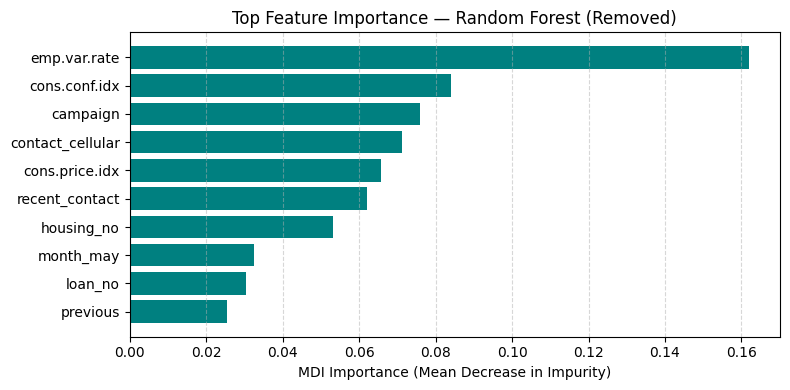

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'clf__max_depth': [None, 10, ...], 'clf__max_features': ['sqrt', 'log2'], 'clf__n_estimators': [100, 200]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter 

Best params for Random Forest (Clipped): {'max_depth': 10, 'max_features': 'sqrt', 'n_estimators': 200} (0:00:25.392696)


,steps,"[('smote', ...), ('clf', ...)]"
,transform_input,None
,memory,None
,verbose,False
,sampling_strategy,'auto'
,random_state,42
,k_neighbors,5
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2


<Figure size 800x400 with 0 Axes>

<BarContainer object of 10 artists>

Text(0.5, 0, 'MDI Importance (Mean Decrease in Impurity)')

Text(0.5, 1.0, 'Top Feature Importance — Random Forest (Clipped)')

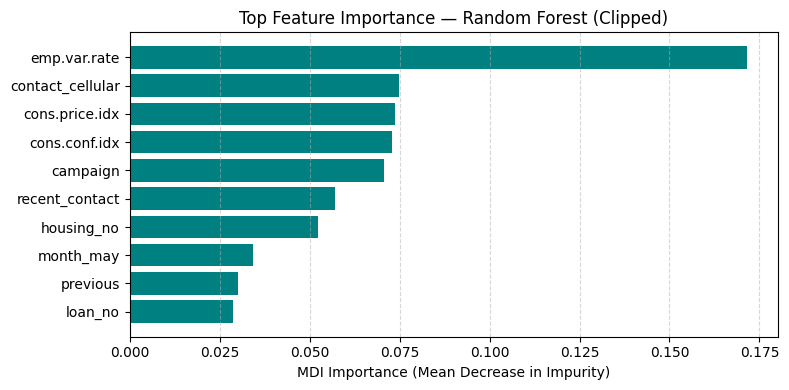

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'clf__max_depth': [None, 10, ...], 'clf__max_features': ['sqrt', 'log2'], 'clf__n_estimators': [100, 200]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter 

Best params for Random Forest - PCA (Removed): {'max_depth': 10, 'max_features': 'sqrt', 'n_estimators': 200} (0:02:10.942826)


,steps,"[('smote', ...), ('clf', ...)]"
,transform_input,None
,memory,None
,verbose,False
,sampling_strategy,'auto'
,random_state,42
,k_neighbors,5
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2


<Figure size 800x400 with 0 Axes>

<BarContainer object of 10 artists>

Text(0.5, 0, 'MDI Importance (Mean Decrease in Impurity)')

Text(0.5, 1.0, 'Top Feature Importance — Random Forest - PCA (Removed)')

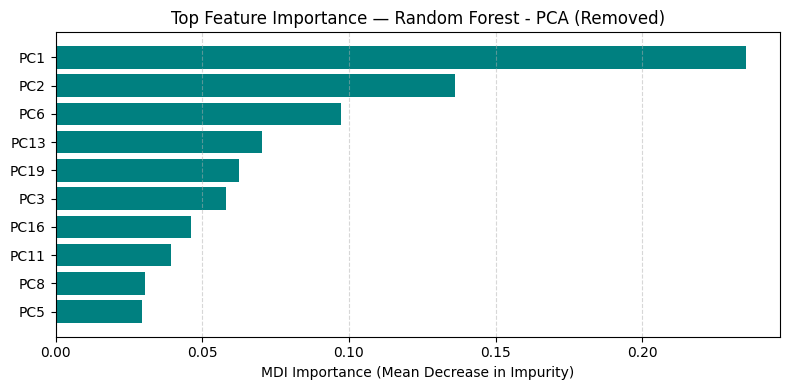

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'clf__max_depth': [None, 10, ...], 'clf__max_features': ['sqrt', 'log2'], 'clf__n_estimators': [100, 200]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter 

Best params for Random Forest - PCA (Clipped): {'max_depth': 10, 'max_features': 'sqrt', 'n_estimators': 200} (0:02:12.145808)


,steps,"[('smote', ...), ('clf', ...)]"
,transform_input,None
,memory,None
,verbose,False
,sampling_strategy,'auto'
,random_state,42
,k_neighbors,5
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2


<Figure size 800x400 with 0 Axes>

<BarContainer object of 10 artists>

Text(0.5, 0, 'MDI Importance (Mean Decrease in Impurity)')

Text(0.5, 1.0, 'Top Feature Importance — Random Forest - PCA (Clipped)')

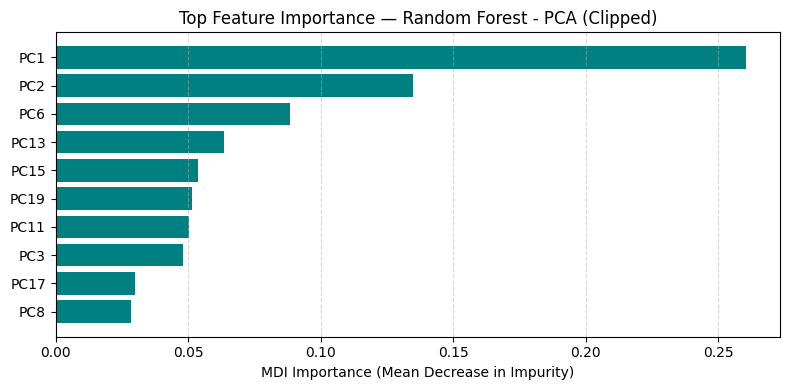

In [ ]:
param_grid = {
    'clf__n_estimators': [100, 200],
    'clf__max_depth':    [None, 10, 20],
    'clf__max_features': ['sqrt', 'log2'],
}

scenarios_rf = [
    ('Random Forest (Removed)',       X_train_selected_removed, y_train_removed),
    ('Random Forest (Clipped)',       X_train_selected_clipped, y_train_clipped),
    ('Random Forest - PCA (Removed)', X_train_pca_removed,      y_train_removed),
    ('Random Forest - PCA (Clipped)', X_train_pca_clipped,      y_train_clipped),
]

for name, X, y in scenarios_rf:
    init_time = time()
    rf_pipe_grid = ImbPipeline([
        ('smote', SMOTE(random_state=42)),
        ('clf', RandomForestClassifier(random_state=42, n_jobs=-1))
    ])
    
    grid_rf = GridSearchCV(rf_pipe_grid, param_grid, cv=3, scoring='average_precision', n_jobs=-1)
    grid_rf.fit(X, y)
    
    best_rf_params = {
        k.replace('clf__', ''): v
        for k, v in grid_rf.best_params_.items()
    }
    print(f"Best params for {name}: {best_rf_params} ({timedelta(seconds=(time()-init_time))})")

    rf_cv_pipe = ImbPipeline([
        ('smote', SMOTE(random_state=42)),
        ('clf', RandomForestClassifier(**best_rf_params, random_state=42, n_jobs=-1))
    ])
    
    cv_rf = cross_validate(rf_cv_pipe, X, y, cv=5, scoring=scoring)
    results_df = add_result_cv(results_df, name, cv_rf)

    rf_cv_pipe.fit(X, y)
    importances = rf_cv_pipe.named_steps['clf'].feature_importances_
    
    feature_names = X.columns if isinstance(X, pd.DataFrame) else [f'PC{i+1}' for i in range(X.shape[1])]
    
    indices = np.argsort(importances)[::-1][:10]
    
    plt.figure(figsize=(8, 4))
    plt.barh([str(feature_names[i]) for i in indices][::-1], importances[indices][::-1], color='teal')
    plt.xlabel('MDI Importance (Mean Decrease in Impurity)')
    plt.title(f'Top Feature Importance — {name}')
    plt.grid(axis='x', linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

In [ ]:
results_df.sort_values(by='AUPR', ascending=False).round(3).set_index('Model')

,F1-score (cv),Precision (cv),Recall (cv),Accuracy (cv),ROC-AUC,AUPR,time
Model,,,,,,,
Lasso Logistic Regression (Clipped),0.661,0.638,0.732,0.815,0.786,0.443,4.656
MLP (Clipped),0.665,0.641,0.736,0.818,0.785,0.441,28.230
Ridge Logistic Regression (Clipped),0.662,0.640,0.735,0.816,0.784,0.441,2.085
Logistic Regression (Clipped),0.662,0.640,0.735,0.816,0.784,0.441,1.750
Lasso Logistic Regression (Removed),0.663,0.640,0.731,0.816,0.783,0.437,4.026
LDA (Clipped),0.655,0.634,0.731,0.808,0.784,0.436,1.690
Ridge Logistic Regression (Removed),0.662,0.639,0.731,0.815,0.783,0.435,1.790
Logistic Regression (Removed),0.662,0.639,0.730,0.815,0.782,0.435,1.716
Random Forest - PCA (Clipped),0.685,0.661,0.734,0.845,0.780,0.434,24.280


### Gradient Boosting

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'clf__learning_rate': [0.01, 0.05, ...], 'clf__max_depth': [3, 5, ...], 'clf__max_iter': [100, 200]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candid

Best params for Gradient Boosting (Removed): {'learning_rate': 0.01, 'max_depth': None, 'max_iter': 200} (0:00:26.296199)


,steps,"[('smote', ...), ('clf', ...)]"
,transform_input,None
,memory,None
,verbose,False
,sampling_strategy,'auto'
,random_state,42
,k_neighbors,5
,"loss loss: {'log_loss'}, default='log_loss'The loss function to use in the boosting process.For binary classification problems, 'log_loss' is also known as logistic loss,binomial deviance or binary crossentropy. Internally, the model fits one treeper boosting iteration and uses the logistic sigmoid function (expit) asinverse link function to compute the predicted positive class probability.For multiclass classification problems, 'log_loss' is also known as multinomialdeviance or categorical crossentropy. Internally, the model fits one tree perboosting iteration and per class and uses the softmax function as inverse linkfunction to compute the predicted probabilities of the classes.",'log_loss'
,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.01
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees for binary classification. For multiclassclassification, `n_classes` trees per iteration are built.",200
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",31


<Figure size 800x400 with 0 Axes>

<BarContainer object of 10 artists>

Text(0.5, 0, 'Permutation Importance (Drop in Average Precision)')

Text(0.5, 1.0, 'Top Feature Importance (Permutation) — Gradient Boosting (Removed)')

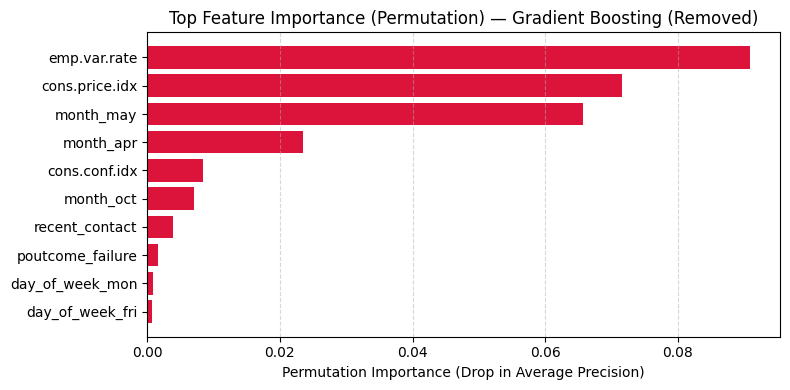

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'clf__learning_rate': [0.01, 0.05, ...], 'clf__max_depth': [3, 5, ...], 'clf__max_iter': [100, 200]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candid

Best params for Gradient Boosting (Clipped): {'learning_rate': 0.05, 'max_depth': None, 'max_iter': 200} (0:00:33.523439)


,steps,"[('smote', ...), ('clf', ...)]"
,transform_input,None
,memory,None
,verbose,False
,sampling_strategy,'auto'
,random_state,42
,k_neighbors,5
,"loss loss: {'log_loss'}, default='log_loss'The loss function to use in the boosting process.For binary classification problems, 'log_loss' is also known as logistic loss,binomial deviance or binary crossentropy. Internally, the model fits one treeper boosting iteration and uses the logistic sigmoid function (expit) asinverse link function to compute the predicted positive class probability.For multiclass classification problems, 'log_loss' is also known as multinomialdeviance or categorical crossentropy. Internally, the model fits one tree perboosting iteration and per class and uses the softmax function as inverse linkfunction to compute the predicted probabilities of the classes.",'log_loss'
,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.05
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees for binary classification. For multiclassclassification, `n_classes` trees per iteration are built.",200
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",31


<Figure size 800x400 with 0 Axes>

<BarContainer object of 10 artists>

Text(0.5, 0, 'Permutation Importance (Drop in Average Precision)')

Text(0.5, 1.0, 'Top Feature Importance (Permutation) — Gradient Boosting (Clipped)')

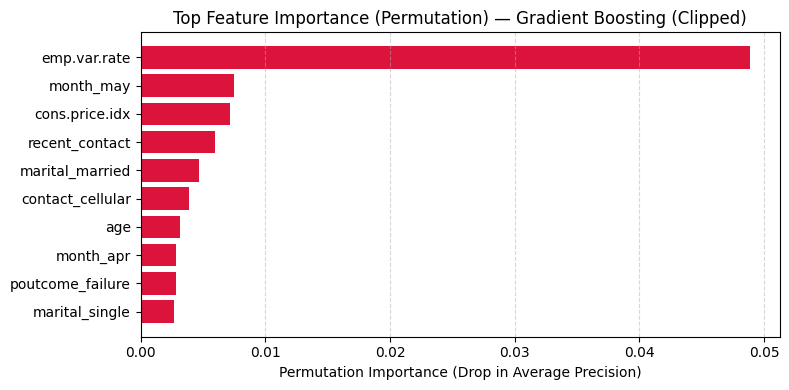

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'clf__learning_rate': [0.01, 0.05, ...], 'clf__max_depth': [3, 5, ...], 'clf__max_iter': [100, 200]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candid

Best params for Gradient Boosting - PCA (Removed): {'learning_rate': 0.01, 'max_depth': 5, 'max_iter': 200} (0:00:17.957115)


,steps,"[('smote', ...), ('clf', ...)]"
,transform_input,None
,memory,None
,verbose,False
,sampling_strategy,'auto'
,random_state,42
,k_neighbors,5
,"loss loss: {'log_loss'}, default='log_loss'The loss function to use in the boosting process.For binary classification problems, 'log_loss' is also known as logistic loss,binomial deviance or binary crossentropy. Internally, the model fits one treeper boosting iteration and uses the logistic sigmoid function (expit) asinverse link function to compute the predicted positive class probability.For multiclass classification problems, 'log_loss' is also known as multinomialdeviance or categorical crossentropy. Internally, the model fits one tree perboosting iteration and per class and uses the softmax function as inverse linkfunction to compute the predicted probabilities of the classes.",'log_loss'
,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.01
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees for binary classification. For multiclassclassification, `n_classes` trees per iteration are built.",200
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",31


<Figure size 800x400 with 0 Axes>

<BarContainer object of 10 artists>

Text(0.5, 0, 'Permutation Importance (Drop in Average Precision)')

Text(0.5, 1.0, 'Top Feature Importance (Permutation) — Gradient Boosting - PCA (Removed)')

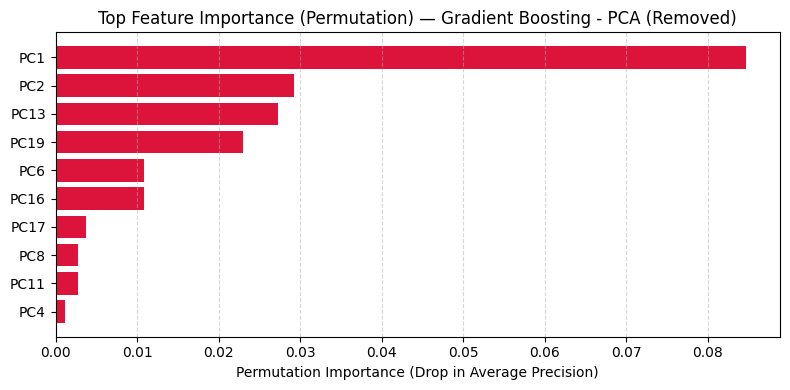

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'clf__learning_rate': [0.01, 0.05, ...], 'clf__max_depth': [3, 5, ...], 'clf__max_iter': [100, 200]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candid

Best params for Gradient Boosting - PCA (Clipped): {'learning_rate': 0.01, 'max_depth': 5, 'max_iter': 200} (0:00:18.217175)


,steps,"[('smote', ...), ('clf', ...)]"
,transform_input,None
,memory,None
,verbose,False
,sampling_strategy,'auto'
,random_state,42
,k_neighbors,5
,"loss loss: {'log_loss'}, default='log_loss'The loss function to use in the boosting process.For binary classification problems, 'log_loss' is also known as logistic loss,binomial deviance or binary crossentropy. Internally, the model fits one treeper boosting iteration and uses the logistic sigmoid function (expit) asinverse link function to compute the predicted positive class probability.For multiclass classification problems, 'log_loss' is also known as multinomialdeviance or categorical crossentropy. Internally, the model fits one tree perboosting iteration and per class and uses the softmax function as inverse linkfunction to compute the predicted probabilities of the classes.",'log_loss'
,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.01
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees for binary classification. For multiclassclassification, `n_classes` trees per iteration are built.",200
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",31


<Figure size 800x400 with 0 Axes>

<BarContainer object of 10 artists>

Text(0.5, 0, 'Permutation Importance (Drop in Average Precision)')

Text(0.5, 1.0, 'Top Feature Importance (Permutation) — Gradient Boosting - PCA (Clipped)')

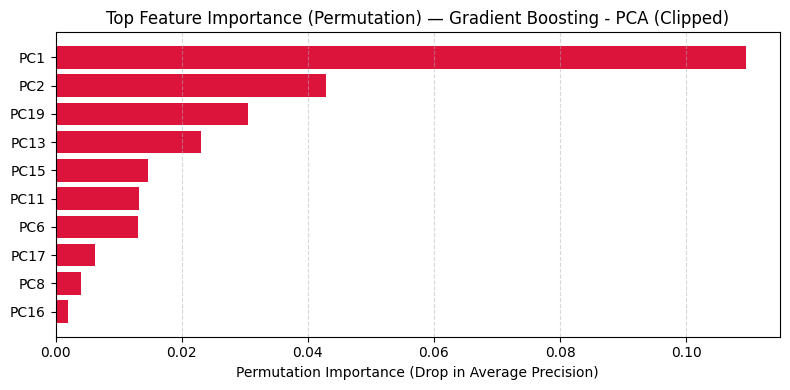

In [ ]:
param_grid_hgb = {
    'clf__learning_rate': [0.01, 0.05, 0.1],
    'clf__max_iter':      [100, 200],
    'clf__max_depth':     [3, 5, None],
}

scenarios_hgb = [
    ('Gradient Boosting (Removed)',       X_train_selected_removed, y_train_removed),
    ('Gradient Boosting (Clipped)',       X_train_selected_clipped, y_train_clipped),
    ('Gradient Boosting - PCA (Removed)', X_train_pca_removed,      y_train_removed),
    ('Gradient Boosting - PCA (Clipped)', X_train_pca_clipped,      y_train_clipped),
]

for name, X, y in scenarios_hgb:
    init_time = time()
    hgb_pipe_grid = ImbPipeline([
        ('smote', SMOTE(random_state=42)),
        ('clf',   HistGradientBoostingClassifier(random_state=42))
    ])
    
    grid_hgb = GridSearchCV(hgb_pipe_grid, param_grid_hgb, cv=3, scoring='average_precision', n_jobs=-1)
    grid_hgb.fit(X, y)
    
    best_hgb_params = {
        k.replace('clf__', ''): v 
        for k, v in grid_hgb.best_params_.items()
    }
    print(f"Best params for {name}: {best_hgb_params} ({timedelta(seconds=(time()-init_time))})")
    
    if name == 'Gradient Boosting (Clipped)':
        best_hgb_params_gridsearch_clipped = best_hgb_params

    hgb_cv_pipe = ImbPipeline([
        ('smote', SMOTE(random_state=42)),
        ('clf',   HistGradientBoostingClassifier(**best_hgb_params, random_state=42))
    ])
    
    cv_hgb = cross_validate(hgb_cv_pipe, X, y, cv=5, scoring=scoring)
    results_df = add_result_cv(results_df, name, cv_hgb)

    hgb_cv_pipe.fit(X, y)
    perm_importance = permutation_importance(hgb_cv_pipe, X, y, n_repeats=5, random_state=42, n_jobs=-1)
    importances_hgb = perm_importance.importances_mean
    feature_names = X.columns if isinstance(X, pd.DataFrame) else [f'PC{i+1}' for i in range(X.shape[1])]
    indices_hgb = np.argsort(importances_hgb)[::-1][:10]
    
    plt.figure(figsize=(8, 4))
    plt.barh([str(feature_names[i]) for i in indices_hgb][::-1], importances_hgb[indices_hgb][::-1], color='crimson')
    plt.xlabel('Permutation Importance (Drop in Average Precision)')
    plt.title(f'Top Feature Importance (Permutation) — {name}')
    plt.grid(axis='x', linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

In [ ]:
results_df.sort_values(by='AUPR', ascending=False).round(3).set_index('Model')

,F1-score (cv),Precision (cv),Recall (cv),Accuracy (cv),ROC-AUC,AUPR,time
Model,,,,,,,
Gradient Boosting (Clipped),0.669,0.747,0.636,0.897,0.784,0.446,14.061
Lasso Logistic Regression (Clipped),0.661,0.638,0.732,0.815,0.786,0.443,4.656
MLP (Clipped),0.665,0.641,0.736,0.818,0.785,0.441,28.230
Ridge Logistic Regression (Clipped),0.662,0.640,0.735,0.816,0.784,0.441,2.085
Logistic Regression (Clipped),0.662,0.640,0.735,0.816,0.784,0.441,1.750
Gradient Boosting (Removed),0.705,0.690,0.726,0.869,0.783,0.438,12.134
Lasso Logistic Regression (Removed),0.663,0.640,0.731,0.816,0.783,0.437,4.026
LDA (Clipped),0.655,0.634,0.731,0.808,0.784,0.436,1.690
Ridge Logistic Regression (Removed),0.662,0.639,0.731,0.815,0.783,0.435,1.790


## Optuna optimization

--- Optimizing Gradient Boosting Optuna (Clipped) with Optuna ---
Best score (AUPR): 0.4489
Best params for Gradient Boosting Optuna (Clipped): {'learning_rate': 0.05334087467046474, 'max_iter': 150, 'max_depth': 9, 'min_samples_leaf': 19, 'l2_regularization': 0.00013420602970420822} (0:02:55.504795)


C:\Users\usuario\AppData\Local\Temp\ipykernel_11304\4235488111.py:31: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  return pd.concat([results_df, pd.DataFrame([row])], ignore_index=True)


,steps,"[('smote', ...), ('clf', ...)]"
,transform_input,None
,memory,None
,verbose,False
,sampling_strategy,'auto'
,random_state,42
,k_neighbors,5
,"loss loss: {'log_loss'}, default='log_loss'The loss function to use in the boosting process.For binary classification problems, 'log_loss' is also known as logistic loss,binomial deviance or binary crossentropy. Internally, the model fits one treeper boosting iteration and uses the logistic sigmoid function (expit) asinverse link function to compute the predicted positive class probability.For multiclass classification problems, 'log_loss' is also known as multinomialdeviance or categorical crossentropy. Internally, the model fits one tree perboosting iteration and per class and uses the softmax function as inverse linkfunction to compute the predicted probabilities of the classes.",'log_loss'
,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.05334087467046474
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees for binary classification. For multiclassclassification, `n_classes` trees per iteration are built.",150
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",31


<Figure size 800x400 with 0 Axes>

<BarContainer object of 10 artists>

Text(0.5, 0, 'Permutation Importance (Drop in Average Precision)')

Text(0.5, 1.0, 'Top Feature Importance (Permutation) — Gradient Boosting Optuna (Clipped)')

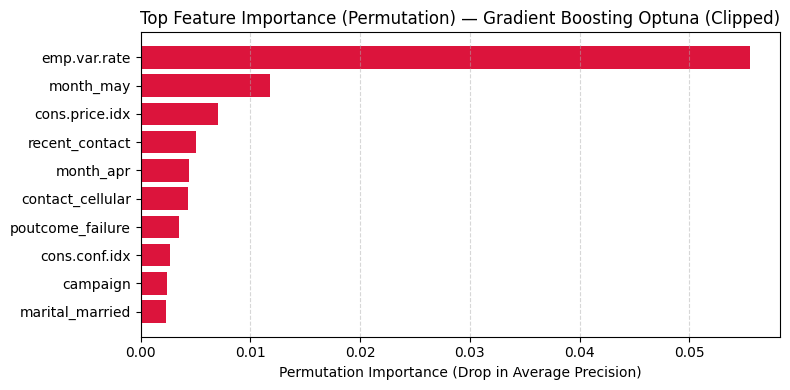

In [58]:
optuna.logging.set_verbosity(optuna.logging.WARNING)

name = 'Gradient Boosting Optuna (Clipped)'
X = X_train_selected_clipped
y = y_train_clipped

print(f"--- Optimizing {name} with Optuna ---")
init_time = time()

def objective(trial):
    params = {
        'learning_rate':     trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        'max_iter':          trial.suggest_int('max_iter', 100, 300, step=50),
        'max_depth':         trial.suggest_int('max_depth', 3, 12),
        'min_samples_leaf':  trial.suggest_int('min_samples_leaf', 10, 50),
        'l2_regularization': trial.suggest_float('l2_regularization', 1e-5, 1.0, log=True)
    }
    
    pipe = ImbPipeline([
        ('smote', SMOTE(random_state=42)),
        ('clf',   HistGradientBoostingClassifier(**params, random_state=42))
    ])
    
    scores = cross_val_score(pipe, X, y, cv=3, scoring=aupr_scorer, n_jobs=-1)
    return scores.mean()

study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=30) 

best_hgb_params_clipped = study.best_params

print(f"Best score (AUPR): {study.best_value:.4f}")
print(f"Best params for {name}: {best_hgb_params_clipped} ({timedelta(seconds=(time()-init_time))})")

hgb_cv_pipe = ImbPipeline([
    ('smote', SMOTE(random_state=42)),
    ('clf',   HistGradientBoostingClassifier(**best_hgb_params_clipped, random_state=42))
])

cv_hgb = cross_validate(hgb_cv_pipe, X, y, cv=5, scoring=scoring)
results_df = add_result_cv(results_df, name, cv_hgb)

hgb_cv_pipe.fit(X_train_selected_clipped, y_train_clipped)
perm_importance = permutation_importance(hgb_cv_pipe, X_train_selected_clipped, y_train_clipped, n_repeats=5, random_state=42, n_jobs=-1)
importances_hgb = perm_importance.importances_mean
feature_names = X.columns if isinstance(X_train_selected_clipped, pd.DataFrame) else [f'PC{i+1}' for i in range(X.shape[1])]
indices_hgb = np.argsort(importances_hgb)[::-1][:10]

plt.figure(figsize=(8, 4))
plt.barh([str(feature_names[i]) for i in indices_hgb][::-1], importances_hgb[indices_hgb][::-1], color='crimson')
plt.xlabel('Permutation Importance (Drop in Average Precision)')
plt.title(f'Top Feature Importance (Permutation) — {name}')
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [ ]:
results_df.sort_values(by='AUPR', ascending=False).round(3).set_index('Model')

,F1-score (cv),Precision (cv),Recall (cv),Accuracy (cv),ROC-AUC,AUPR,time
Model,,,,,,,
Gradient Boosting Optuna (Clipped),0.677,0.742,0.646,0.896,0.784,0.448,10.079
Gradient Boosting (Clipped),0.669,0.747,0.636,0.897,0.784,0.446,14.061
Lasso Logistic Regression (Clipped),0.661,0.638,0.732,0.815,0.786,0.443,4.656
MLP (Clipped),0.665,0.641,0.736,0.818,0.785,0.441,28.230
Ridge Logistic Regression (Clipped),0.662,0.640,0.735,0.816,0.784,0.441,2.085
Logistic Regression (Clipped),0.662,0.640,0.735,0.816,0.784,0.441,1.750
Gradient Boosting (Removed),0.705,0.690,0.726,0.869,0.783,0.438,12.134
Lasso Logistic Regression (Removed),0.663,0.640,0.731,0.816,0.783,0.437,4.026
LDA (Clipped),0.655,0.634,0.731,0.808,0.784,0.436,1.690


# Model Selection and Validation

,"strategy strategy: {""most_frequent"", ""prior"", ""stratified"", ""uniform"", ""constant""}, default=""prior""Strategy to use to generate predictions.* ""most_frequent"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit`. The `predict_proba` method returns the matching one-hot encoded vector.* ""prior"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit` (like ""most_frequent""). ``predict_proba`` always returns the empirical class distribution of `y` also known as the empirical class prior distribution.* ""stratified"": the `predict_proba` method randomly samples one-hot vectors from a multinomial distribution parametrized by the empirical class prior probabilities. The `predict` method returns the class label which got probability one in the one-hot vector of `predict_proba`. Each sampled row of both methods is therefore independent and identically distributed.* ""uniform"": generates predictions uniformly at random from the list of unique classes observed in `y`, i.e. each class has equal probability.* ""constant"": always predicts a constant label that is provided by the user. This is useful for metrics that evaluate a non-majority class. .. versionchanged:: 0.24 The default value of `strategy` has changed to ""prior"" in version 0.24.",'most_frequent'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness to generate the predictions when``strategy='stratified'`` or ``strategy='uniform'``.Pass an int for reproducible output across multiple function calls.See :term:`Glossary `.",42
,"constant constant: int or str or array-like of shape (n_outputs,), default=NoneThe explicit constant as predicted by the ""constant"" strategy. Thisparameter is useful only for the ""constant"" strategy.",None


=== Baseline Comparison on Test Set ===

Dummy Classifier
  Accuracy  : 0.887
  Precision : 0.000
  Recall    : 0.000
  F1-score  : 0.000
  ROC-AUC   : 0.500
  AUPR      : 0.113



,"loss loss: {'log_loss'}, default='log_loss'The loss function to use in the boosting process.For binary classification problems, 'log_loss' is also known as logistic loss,binomial deviance or binary crossentropy. Internally, the model fits one treeper boosting iteration and uses the logistic sigmoid function (expit) asinverse link function to compute the predicted positive class probability.For multiclass classification problems, 'log_loss' is also known as multinomialdeviance or categorical crossentropy. Internally, the model fits one tree perboosting iteration and per class and uses the softmax function as inverse linkfunction to compute the predicted probabilities of the classes.",'log_loss'
,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.05334087467046474
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees for binary classification. For multiclassclassification, `n_classes` trees per iteration are built.",150
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",31
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",9
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",19
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",0.00013420602970420822
,"max_features max_features: float, default=1.0Proportion of randomly chosen features in each and every node split.This is a form of regularization, smaller values make the trees weakerlearners and might prevent overfitting.If interaction constraints from `interaction_cst` are present, only allowedfeatures are taken into account for the subsampling... versionadded:: 1.4",1.0
,"max_bins max_bins: int, default=255The maximum number of bins to use for non-missing values. Beforetraining, each feature of the input array `X` is binned intointeger-valued bins, which allows for a much faster training stage.Features with a small number of unique values may use less than``max_bins`` bins. In addition to the ``max_bins`` bins, one more binis always reserved for missing values. Must be no larger than 255.",255
,"categorical_features categorical_features: array-like of {bool, int, str} of shape (n_features) or shape (n_categorical_features,), default='from_dtype'Indicates the categorical features.- None : no feature will be considered categorical.- boolean array-like : boolean mask indicating categorical features.- integer array-like : integer indices indicating categorical features.- str array-like: names of categorical features (assuming the training data has feature names).- `""from_dtype""`: dataframe columns with dtype ""category"" are considered to be categorical features. The input must be an object exposing a ``__dataframe__`` method such as pandas or polars DataFrames to use this feature.For each categorical feature, there must be at most `max_bins` uniquecategories. Negative values for categorical features encoded as numericdtypes are treated as missing values. All categorical values areconverted to floating point numbers. This means that categorical valuesof 1.0 and 1 are treated as the same category.Read more in the :ref:`User Guide `... versionadded:: 0.24.. versionchanged:: 1.2 Added support for feature names... versionchanged:: 1.4 Added `""from_dtype""` option... versionchanged:: 1.6 The default value changed from `None

Best threshold (F1): 0.297

=== Gradient Boosting — Final Test Evaluation (Clipped) ===
  Accuracy  : 0.880
  Precision : 0.474
  Recall    : 0.553
              precision    recall  f1-score   support

           0       0.94      0.92      0.93     12058
           1       0.47      0.55      0.51      1531

    accuracy                           0.88     13589
   macro avg       0.71      0.74      0.72     13589
weighted avg       0.89      0.88      0.88     13589

ROC-AUC: 0.7937563424939702
AUPR:    0.4623702521802702


<Axes: >

Text(0.5, 23.52222222222222, 'Predicted')

Text(50.722222222222214, 0.5, 'Actual')

Text(0.5, 1.0, 'Confusion Matrix — Gradient Boosting (Test Set)')

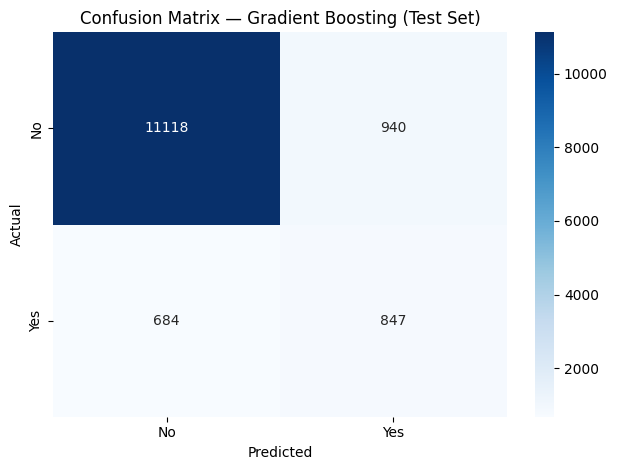

Text(0.5, 1.0, 'ROC Curve — Test Set')

Text(0.5, 1.0, 'Precision-Recall Curve — Test Set')

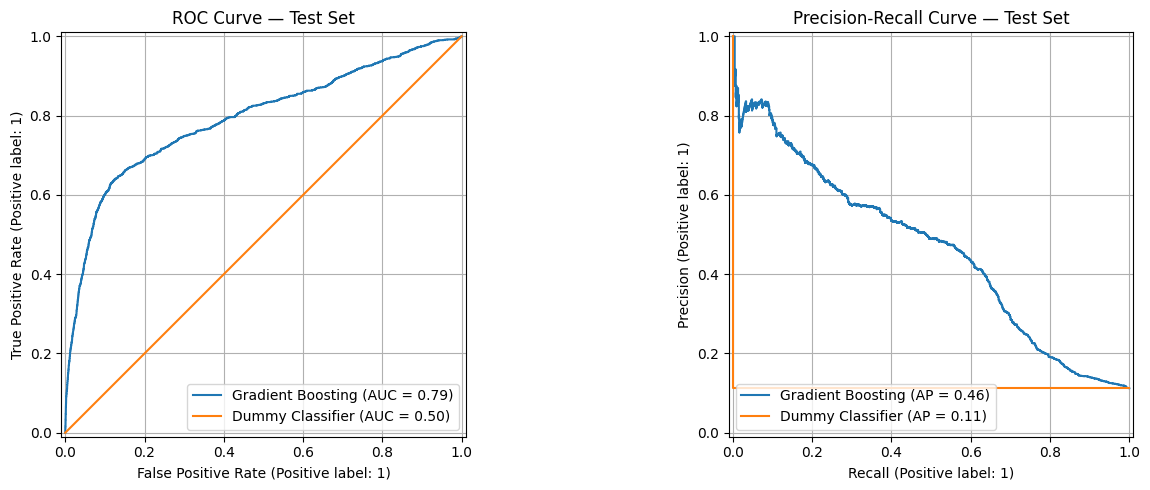

In [59]:
# Step 1 — Compute the baseline on the test set

sm = SMOTE(random_state=42)
X_train_res_final, y_train_res_final = sm.fit_resample(X_train_selected_clipped, y_train_clipped)

dummy_final = DummyClassifier(strategy='most_frequent', random_state=42)
dummy_final.fit(X_train_res_final, y_train_res_final)

print("=== Baseline Comparison on Test Set ===\n")
y_proba_base = dummy_final.predict_proba(X_test_filtered_clipped)[:, 1]
y_pred_base  = dummy_final.predict(X_test_filtered_clipped)
print("Dummy Classifier")
print(f"  Accuracy  : {accuracy_score(y_test_clipped, y_pred_base):.3f}")
print(f"  Precision : {precision_score(y_test_clipped, y_pred_base, zero_division=0):.3f}")
print(f"  Recall    : {recall_score(y_test_clipped, y_pred_base, zero_division=0):.3f}")
print(f"  F1-score  : {f1_score(y_test_clipped, y_pred_base, zero_division=0):.3f}")
print(f"  ROC-AUC   : {roc_auc_score(y_test_clipped, y_proba_base):.3f}")
print(f"  AUPR      : {average_precision_score(y_test_clipped, y_proba_base):.3f}\n")

# Step 2 - Train final best model

hgb_final = HistGradientBoostingClassifier(**best_hgb_params_clipped, random_state=42)
hgb_final.fit(X_train_res_final, y_train_res_final)

# Step 3 — Threshold optimization using out-of-fold predictions
hgb_thresh = ImbPipeline([
    ('smote', SMOTE(random_state=42)),
    ('clf',   HistGradientBoostingClassifier(**best_hgb_params_clipped, random_state=42))
])
y_proba_cv = cross_val_predict(hgb_thresh, X_train_selected_clipped, y_train_clipped, cv=5, method='predict_proba', n_jobs=-1)[:, 1]

thresholds = np.linspace(0, 1, 1000)
f1_scores  = [f1_score(y_train_clipped, (y_proba_cv >= t).astype(int)) for t in thresholds]
best_t     = thresholds[np.argmax(f1_scores)]
print(f"Best threshold (F1): {best_t:.3f}")

# Step 4 — Final test evaluation
y_proba_test = hgb_final.predict_proba(X_test_filtered_clipped)[:, 1]
y_pred_test  = (y_proba_test >= best_t).astype(int)

print("\n=== Gradient Boosting — Final Test Evaluation (Clipped) ===")
print(f"  Accuracy  : {accuracy_score(y_test_clipped, y_pred_test):.3f}")
print(f"  Precision : {precision_score(y_test_clipped, y_pred_test):.3f}")
print(f"  Recall    : {recall_score(y_test_clipped, y_pred_test):.3f}")
print(classification_report(y_test_clipped, y_pred_test))
print("ROC-AUC:", roc_auc_score(y_test_clipped, y_proba_test))
print("AUPR:   ", average_precision_score(y_test_clipped, y_proba_test))

# Step 5 — Confusion matrix
cm = confusion_matrix(y_test_clipped, y_pred_test)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['No', 'Yes'], yticklabels=['No', 'Yes'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix — Gradient Boosting (Test Set)')
plt.tight_layout()
plt.show()

# Step 6 — ROC and PR curves comparing final model vs dummy baseline
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

RocCurveDisplay.from_predictions(y_test_clipped, y_proba_test, ax=axes[0], name='Gradient Boosting')
PrecisionRecallDisplay.from_predictions(y_test_clipped, y_proba_test, ax=axes[1], name='Gradient Boosting')

RocCurveDisplay.from_predictions(y_test_clipped, y_proba_base, ax=axes[0], name='Dummy Classifier')
PrecisionRecallDisplay.from_predictions(y_test_clipped, y_proba_base, ax=axes[1], name='Dummy Classifier')

axes[0].set_title('ROC Curve — Test Set')
axes[0].grid(True)
axes[1].set_title('Precision-Recall Curve — Test Set')
axes[1].grid(True)

plt.tight_layout()
plt.show()